# 1. Objetivo do Trabalho

**Probabilidade de uma ocorrencia futura de acidente de transito em MG na BR 381 ser classificada como Risco Elevado (feridos graves ou mortos)**

Foi realizado uma análise exploratória, utilizando fatores descritivos dos eventos, tais como: período do dia, situação meteorológica, zona, traçado da via, sentido da via, tipo da pista, tipo e causa do acidente, br  e fatores quantitativos (pessoas, veículos), considerando o histórico das ocorrências (de Janeiro/2022 a Outubro/2023) e  então construído um modelo de predição utilizando modelos estatísticos aplicado em Novembro/2023 para verificar a performance do modelo (out-of-time).

A partir disso, foram realizadas predições utilizando algoritmos de Inteligência Artificial (Machine e Deep Learning), que selecionaram as características mais relevantes, tendências nos dados nos permitindo predizer ocorrências.


# 2. Contextualização do Problema

A **Polícia Rodoviária Federal** é  detentora da informação referente as ocorrências de acidentes de trânsitos e em meio ao acompanhamento e analise identificaram que além de Minas Gerais ser o top 1 em  ATR (acidentes de trânsito nas rodovias) , o mesmo ocorre na BR 381 de Minas Gerais.

Visando uma nova estratégia para a Operação (onde ocorre fiscalização nas rodovias, policiais patrulham a área com maiores ocorrências  com o objetivo de conter alvoroços e imprudências) e ter a dimensão da necessidade de acionamento de outras equipes como SAMU ou BOMBEIROS, além de colaborar com o SAMU para dar uma visibilidade da possibilidade de ocorrências mais críticas , contrataram uma Consultoria para realizar um estudo com os dados histórico das ocorrências (de Janeiro/2022 a Outubro/2023) , com a finalidade de identificar as características dos locais mais ofensores no Estado de Minas Gerais na BR 381 e então predizer a possibilidade do evento ocorrer ou não em casos de ocorrências com feridos graves ou mortes.

Desta maneira o modelo auxiliará a Policia Rodoviária Federal a direcionarem suas ações com o público mais específico e com mais coerência a quantidade de policias e equipes envolvidas e necessárias destinados para fiscalização e apoio posterior.


In [ ]:
!pip install feature-engine catboost lightgbm xgboost dask-expr # Instalação de pacotes para machine learning, manipulação de dados e otimização

# 3. Base de Dados
Visão da base  : Ocorrências de acidente de trânsito nas rodovias brasileiras.

Filtros de Inclusão:
 - Ano_mês_ocorrência, mês_ocorrência, a partir da data da ocorrência
 - Região, a partir da UF
 - Periodo_dia a partir do horário
 - Causa_acidente_agg, a partir da causa_acidente
 - Tipo_acidente_categ a partir do tipo_acidente
 - Houve Mortes, a partir da coluna mortos
 - Zona, a partir da coluna uso_solo


Filtros de Exclusão:
 - Colunas que não são necessárias na base, pois contem divergência, ou foram categorizadas, ou causariam conflito com a variável target: (horario, km, municipio, causa_acidente, tipo_acidente, classificação_acidente, fase_dia,  uso_solo , traçado_via, mortos, feridos_leves, feridos_graves, ilesos, ignorados, feridos)


Período de Análise:
 - Tabela unificada com dados de (22meses): Jan/2022 a Out/2023
 - Previsão: Nov/23 para testar o modelo
 - De um total de 25 colunas, adicionei 7 colunas e removi 14 colunas , totalizando 18 colunas.
 - De um total de 125.563 registros, ao filtrar o Estado de MG > BR 381  reduzi para 4.605 registros.
 - Fonte de dados: Site Gov.br > Policia Rodoviária Federal > Acidentes : https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf


> A análise exploratória e a regressão logística tradicional foram feitas em R: veja `r/01_higienizacao_eda_regressao_logistica.R`. Este notebook parte da base já tratada.

In [ ]:
import pandas as pd

# Carregar os datasets
df_ocorrencia = pd.read_csv('../data/base_acidente_transito_MG_381_v2.csv')


# Verificar o período dos dados no dataset de pedidos
df_ocorrencia['data_inversa'] = pd.to_datetime(df_ocorrencia['data_inversa'])

df_ocorrencia['data_inversa'].agg(('min', 'max'))


,data_inversa
min,2022-01-01
max,2023-10-31


In [ ]:
df_ocorrencia.head(5)

,id,data_inversa,dia_semana,uf,br,sentido_via,condicao_metereologica,tipo_pista,tracado_via,pessoas,veiculos,ano_mes_ocorrencia,mes_ocorrencia,periodo_dia,Regiao,causa_acidente_agg,zona,houve_mortos_ou_feridos_graves,tipo_acidente_categ
0,405466,2022-01-02,domingo,MG,381,Crescente,Chuva,Dupla,Reta,1,1,2022-01,1,Tarde,Sudeste,Fator Humano,Rural,0,Saída de leito carroçável
1,405701,2022-01-03,segunda-feira,MG,381,Crescente,Nublado,Dupla,Reta,1,1,2022-01,1,Manhã,Sudeste,Fator Humano,Rural,0,Saída de leito carroçável
2,405820,2022-01-03,segunda-feira,MG,381,Crescente,Chuva,Simples,Curva,3,2,2022-01,1,Noite,Sudeste,Fator Via/ Natureza,Rural,0,Colisão
3,405940,2022-01-04,terça-feira,MG,381,Decrescente,Nublado,Simples,Curva,7,4,2022-01,1,Tarde,Sudeste,Fator Humano,Rural,1,Colisão
4,406053,2022-01-05,quarta-feira,MG,381,Crescente,Chuva,Dupla,NaN,6,2,2022-01,1,Manhã,Sudeste,Fator Humano,Rural,0,Colisão


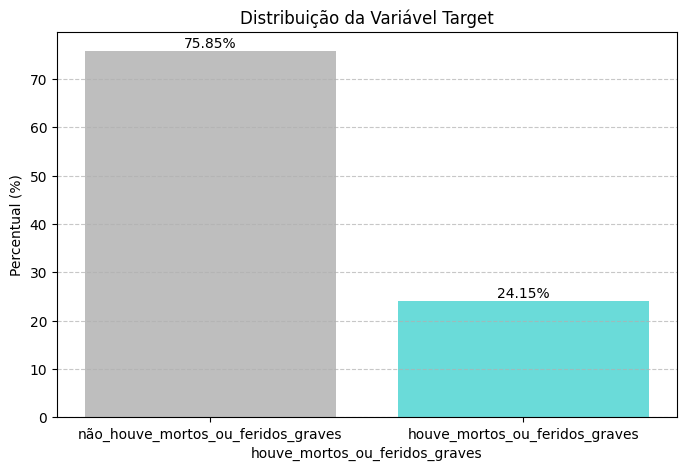

In [ ]:
#distribuição da variavel target
import matplotlib.pyplot as plt
import seaborn as sns
target_counts = df_ocorrencia['houve_mortos_ou_feridos_graves'].value_counts()
target_percent = (target_counts / target_counts.sum()) * 100

plt.figure(figsize=(8, 5))
bars = plt.bar(target_counts.index.astype(str), target_percent, color=['#BEBEBE', '#6ADBD9'])
plt.title('Distribuição da Variável Target')
plt.xlabel('houve_mortos_ou_feridos_graves')
plt.ylabel('Percentual (%)')
plt.xticks([0, 1], ['não_houve_mortos_ou_feridos_graves', 'houve_mortos_ou_feridos_graves'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adicionar rótulos nas barras
for bar, percent in zip(bars, target_percent):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{percent:.2f}%', va='bottom', ha='center')

plt.show()

## Criação da ABT

In [ ]:
#Ja havia feito a analise exploratoria e seleção dos dados na Entrega 2, estou seguindo com a base da entrega 2 como minha ABT
df_abt = df_ocorrencia
df_abt.head(5)

,id,data_inversa,dia_semana,uf,br,sentido_via,condicao_metereologica,tipo_pista,tracado_via,pessoas,veiculos,ano_mes_ocorrencia,mes_ocorrencia,periodo_dia,Regiao,causa_acidente_agg,zona,houve_mortos_ou_feridos_graves,tipo_acidente_categ
0,405466,2022-01-02,domingo,MG,381,Crescente,Chuva,Dupla,Reta,1,1,2022-01,1,Tarde,Sudeste,Fator Humano,Rural,0,Saída de leito carroçável
1,405701,2022-01-03,segunda-feira,MG,381,Crescente,Nublado,Dupla,Reta,1,1,2022-01,1,Manhã,Sudeste,Fator Humano,Rural,0,Saída de leito carroçável
2,405820,2022-01-03,segunda-feira,MG,381,Crescente,Chuva,Simples,Curva,3,2,2022-01,1,Noite,Sudeste,Fator Via/ Natureza,Rural,0,Colisão
3,405940,2022-01-04,terça-feira,MG,381,Decrescente,Nublado,Simples,Curva,7,4,2022-01,1,Tarde,Sudeste,Fator Humano,Rural,1,Colisão
4,406053,2022-01-05,quarta-feira,MG,381,Crescente,Chuva,Dupla,NaN,6,2,2022-01,1,Manhã,Sudeste,Fator Humano,Rural,0,Colisão


In [ ]:
df_abt['houve_mortos_ou_feridos_graves'].mean()

0.24147665580890337

In [ ]:
df_abt.shape

(4605, 19)

In [ ]:
df_abt.dtypes

,0
id,int64
data_inversa,datetime64[ns]
dia_semana,object
uf,object
br,int64
sentido_via,object
condicao_metereologica,object
tipo_pista,object
tracado_via,object
pessoas,int64


# 4. Modelagem com Estatística Tradicional
A versão oficial desta etapa está no script R (`r/01_higienizacao_eda_regressao_logistica.R`), que inclui a matriz de confusão e o cálculo de custo. A reexecução em Python abaixo apresentou pequenas variações numéricas; os resultados reportados no README são os do R.

In [ ]:
#SEPARANDO EM TREINO E OOT. SENDO QUE NO TREINO E TESTE A SEPARAÇÃO FOI DE 70% E 30%, E FOI CONSIDERADO O STRATIFY = Y, PARA MANTER A MESMA DISTRIBUICAO NAS BASES TREINO E TESTE
from sklearn.model_selection import train_test_split
import pandas as pd

# Base de treinamento e teste
df_train_oot = df_abt


# Definição das variáveis
key_vars = ['uf', 'br', 'Regiao', 'id','data_inversa']
num_vars = ['pessoas', 'veiculos', 'mes_ocorrencia']
cat_vars = ['dia_semana','sentido_via','condicao_metereologica','tipo_pista','tracado_via','ano_mes_ocorrencia','periodo_dia','causa_acidente_agg','zona','tipo_acidente_categ']
target = 'houve_mortos_ou_feridos_graves'

features = cat_vars + num_vars

# Preparar X e y para o treino e teste
X_train_oot = df_train_oot[features]
y_train_oot = df_train_oot[target]


# Criar dummies para todo o DataFrame
df_dummies = pd.get_dummies(X_train_oot, drop_first=True)


# Adicionar a coluna target ao DataFrame de dummies
df_dummies[target] = y_train_oot


# Separar a base de treino e teste
X_train, X_oot, y_train, y_oot = train_test_split(df_dummies.drop(columns=target),
                                                   df_dummies[target],
                                                   test_size=0.3,
                                                   random_state=42,
                                                   stratify=df_dummies[target])


# Verificar as formas dos DataFrames resultantes
print(f"Treinamento: {X_train.shape}, {y_train.shape}")
print(f"oot: {X_oot.shape}, {y_oot.shape}")



Treinamento: (3223, 59), (3223,)
oot: (1382, 59), (1382,)


In [ ]:
#forço para numericas
X_train = X_train.astype(int)
X_oot = X_oot.astype(int)

In [ ]:
print(X_train.dtypes)
print(X_oot.dtypes)

pessoas                                          int64
veiculos                                         int64
mes_ocorrencia                                   int64
dia_semana_quarta-feira                          int64
dia_semana_quinta-feira                          int64
dia_semana_segunda-feira                         int64
dia_semana_sexta-feira                           int64
dia_semana_sábado                                int64
dia_semana_terça-feira                           int64
sentido_via_Decrescente                          int64
condicao_metereologica_Céu Claro                 int64
condicao_metereologica_Garoa/Chuvisco            int64
condicao_metereologica_Granizo                   int64
condicao_metereologica_Nevoeiro/Neblina          int64
condicao_metereologica_Nublado                   int64
condicao_metereologica_Sol                       int64
tipo_pista_Múltipla                              int64
tipo_pista_Simples                               int64
tracado_vi

In [ ]:
!pip install scorecardpy

In [ ]:
#Analisando o IV - relevancia das variaveis
import pandas as pd
import scorecardpy as sc

# Verificar o tipo de y_train e o formato
print(f"Tipo de y_train: {type(y_train)}")
print(f"Shape de y_train: {y_train.shape}")

# Transformar y_train em DataFrame
y_train_df = pd.DataFrame(y_train).reset_index(drop=True)

# Adicionar y_train como uma coluna em X_train
X_train_with_y = X_train.copy()
X_train_with_y['target'] = y_train_df

# Calcular o IV
iv = sc.iv(X_train_with_y, 'target')

# Exibir o IV ordenado por valor
iv_sorted = iv.sort_values(by='info_value', ascending=False)
print(iv_sorted)

Tipo de y_train: <class 'pandas.core.series.Series'>
Shape de y_train: (3223,)


/usr/local/lib/python3.10/dist-packages/scorecardpy/condition_fun.py:125: UserWarning: There are NaNs in 'target' column. The rows with NaN in 'target' were removed from dat.
  warnings.warn("There are NaNs in \'{}\' column. The rows with NaN in \'{}\' were removed from dat.".format(y,y))
/usr/local/lib/python3.10/dist-packages/scorecardpy/condition_fun.py:141: UserWarning: The positive value in "target" was replaced by 1 and negative value by 0.
  warnings.warn("The positive value in \"{}\" was replaced by 1 and negative value by 0.".format(y))
/usr/local/lib/python3.10/dist-packages/scorecardpy/condition_fun.py:147: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat[y] = dat[y].astype('int')


                                         variable  info_value
57                                        pessoas    4.077901
8                                        veiculos    3.463403
9                               tracado_via_Túnel    3.302573
30                            tracado_via_Viaduto    3.041986
39                              tracado_via_Ponte    2.948384
0                           tracado_via_Rotatória    2.868941
36              tracado_via_Retorno Regulamentado    2.738733
29                 tracado_via_Interseção de vias    2.738733
7         condicao_metereologica_Nevoeiro/Neblina    2.404217
34                  tracado_via_Desvio Temporário    2.061238
16                     ano_mes_ocorrencia_2023-05    1.951073
10                     ano_mes_ocorrencia_2023-02    1.896089
56                     ano_mes_ocorrencia_2023-10    1.883080
17                     ano_mes_ocorrencia_2023-08    1.883080
21                     ano_mes_ocorrencia_2023-03    1.845619
28      

In [ ]:
#MODELO DE REGRESSAO LOGISTICA TRADICIONAL SOMENTE COM AS FEATURES COM IV RELEVANTE: DESCONSIDEREI (SENTIDO_VIA, DIA_SEMANA, MES_OCORRENCIA, PERIODO_DIA, ZONA) MANTIVE APENAS AS VARIAVEIS COM IV ALTO E SOMENTE A TIPO PISTA COM IV MODERADO

import statsmodels.api as sm

# Adicionando o intercepto ao X_train
X_train_with_const = sm.add_constant(X_train[['pessoas', 'veiculos', 'causa_acidente_agg_Fator Veicular',
                                              'causa_acidente_agg_Fator Via/ Natureza', 'tipo_acidente_categ_Capotamento',
                                              'tipo_acidente_categ_Colisão', 'tipo_acidente_categ_Engavetamento',
                                              'tipo_acidente_categ_Outros', 'tipo_acidente_categ_Saída de leito carroçável',
                                              'tipo_acidente_categ_Tombamento', 'tipo_pista_Múltipla', 'tipo_pista_Simples']])

# Ajustando o modelo
logit_model = sm.Logit(y_train, X_train_with_const).fit()

# Resumo do modelo
logit_model_summary = logit_model.summary()

print(logit_model_summary)


Optimization terminated successfully.
         Current function value: 0.512369
         Iterations 6
                                 Logit Regression Results                                 
Dep. Variable:     houve_mortos_ou_feridos_graves   No. Observations:                 3223
Model:                                      Logit   Df Residuals:                     3210
Method:                                       MLE   Df Model:                           12
Date:                            Sat, 05 Oct 2024   Pseudo R-squ.:                 0.07293
Time:                                    12:43:52   Log-Likelihood:                -1651.4
converged:                                   True   LL-Null:                       -1781.3
Covariance Type:                        nonrobust   LLR p-value:                 1.218e-48
                                                    coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------

Métricas e Matriz de Confusão para o Treino
              precision    recall  f1-score   support

           0       0.84      0.64      0.73      2445
           1       0.35      0.60      0.44       778

    accuracy                           0.63      3223
   macro avg       0.59      0.62      0.58      3223
weighted avg       0.72      0.63      0.66      3223

Acurácia: 0.63
Acurácia Balanceada: 0.62
Especificidade: 0.64
Sensibilidade: 0.60
AUC: 0.68


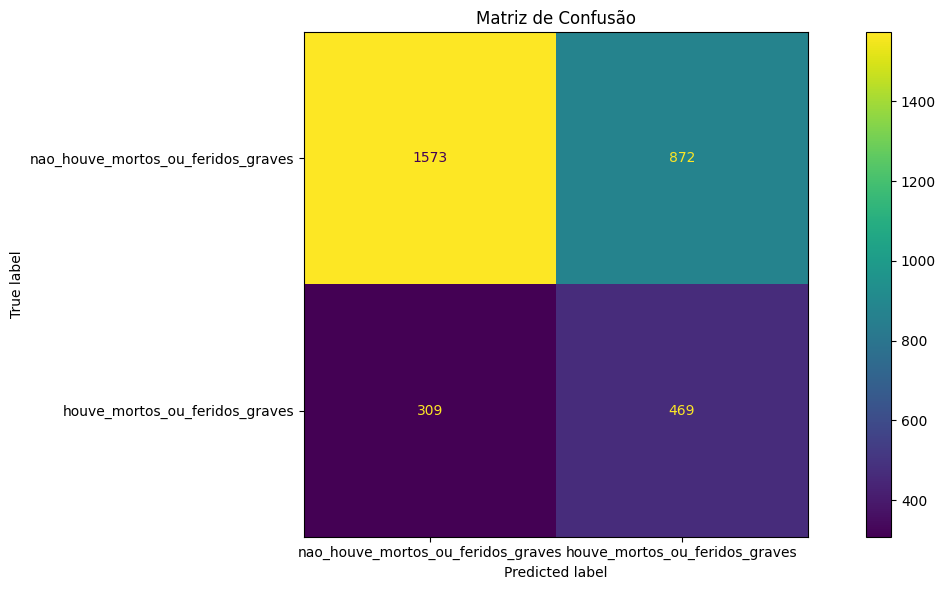

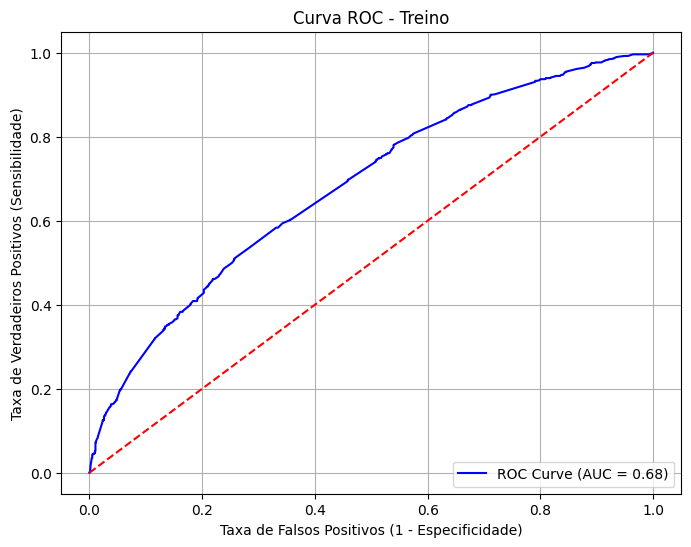

Métricas e Matriz de Confusão para o OOT
              precision    recall  f1-score   support

           0       0.84      0.65      0.73      1048
           1       0.35      0.61      0.45       334

    accuracy                           0.64      1382
   macro avg       0.60      0.63      0.59      1382
weighted avg       0.72      0.64      0.66      1382

Acurácia: 0.64
Acurácia Balanceada: 0.63
Especificidade: 0.65
Sensibilidade: 0.61
AUC: 0.68


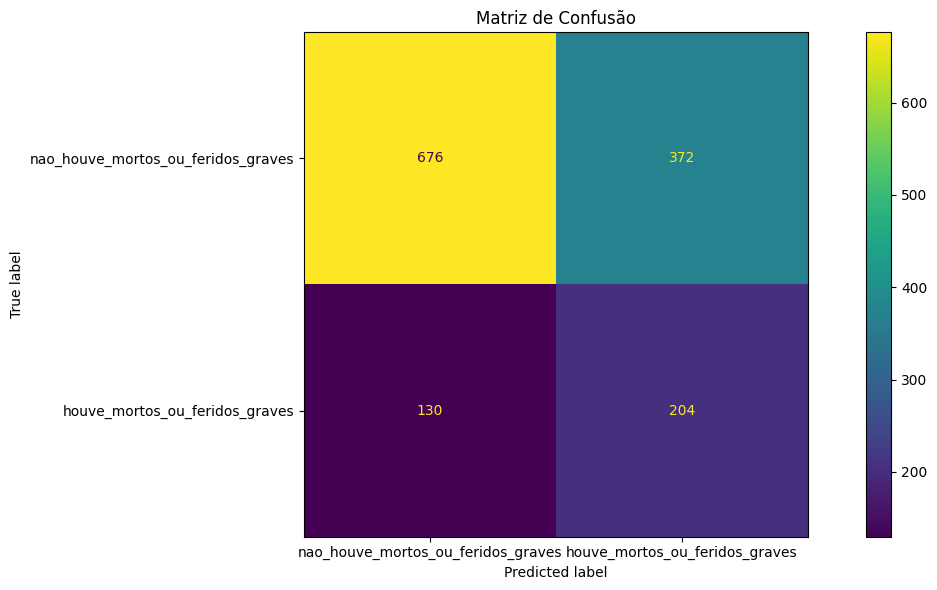

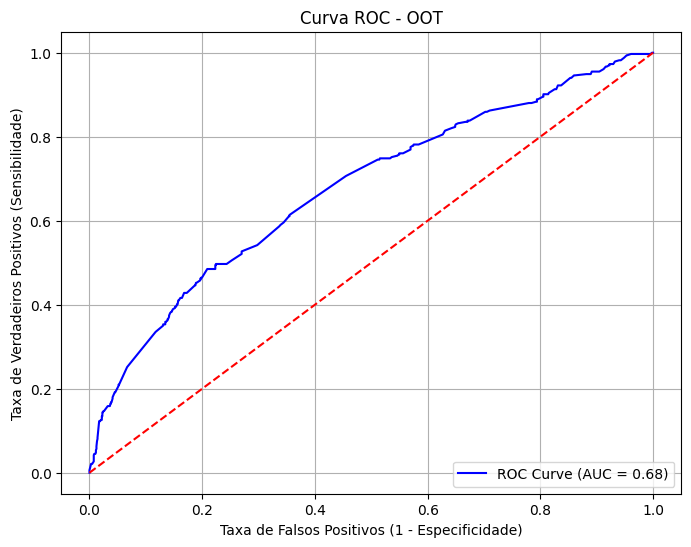

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             accuracy_score, balanced_accuracy_score, recall_score, precision_score,
                             roc_curve, roc_auc_score)
import statsmodels.api as sm

# Função para plotar a matriz de confusão
def plot_confusion_matrix(y_true, y_pred=None, display_labels=['nao_houve_mortos_ou_feridos_graves', 'houve_mortos_ou_feridos_graves'], figsize=(12, 6)):
    fig, axes = plt.subplots(figsize=figsize)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, values_format='d', display_labels=display_labels, ax=axes)
    axes.set_title('Matriz de Confusão')
    plt.tight_layout()
    plt.show()

# Função para calcular as métricas de classificação, incluindo AUC
def exibir_metricas_classificacao(y_true, y_pred, y_scores, labels=None):
    # Exibe o relatório de classificação
    print(classification_report(y_true, y_pred, labels=labels, zero_division=0))

    # Calcula a matriz de confusão
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    sensitivity = recall_score(y_true, y_pred)

    # Calcula a AUC
    auc_score = roc_auc_score(y_true, y_scores)

    # Exibe as métricas
    print(f'Acurácia: {accuracy_score(y_true, y_pred):.2f}')
    print(f'Acurácia Balanceada: {balanced_accuracy_score(y_true, y_pred):.2f}')
    print(f'Especificidade: {specificity:.2f}')
    print(f'Sensibilidade: {sensitivity:.2f}')
    print(f'AUC: {auc_score:.2f}')  # Adiciona a AUC aqui

# Função para plotar a curva ROC
def plot_roc_curve(y_true, y_scores, title="Curva ROC"):
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    auc_score = roc_auc_score(y_true, y_scores)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--')  # Linha de referência
    plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
    plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

# Adicionando o intercepto aos conjuntos de treino e OOT
X_train_with_const = sm.add_constant(X_train[['pessoas', 'veiculos', 'causa_acidente_agg_Fator Veicular',
                                              'causa_acidente_agg_Fator Via/ Natureza', 'tipo_acidente_categ_Capotamento',
                                              'tipo_acidente_categ_Colisão', 'tipo_acidente_categ_Engavetamento',
                                              'tipo_acidente_categ_Outros', 'tipo_acidente_categ_Saída de leito carroçável',
                                              'tipo_acidente_categ_Tombamento', 'tipo_pista_Múltipla', 'tipo_pista_Simples']])

X_oot_with_const = sm.add_constant(X_oot[['pessoas', 'veiculos', 'causa_acidente_agg_Fator Veicular',
                                          'causa_acidente_agg_Fator Via/ Natureza', 'tipo_acidente_categ_Capotamento',
                                          'tipo_acidente_categ_Colisão', 'tipo_acidente_categ_Engavetamento',
                                          'tipo_acidente_categ_Outros', 'tipo_acidente_categ_Saída de leito carroçável',
                                          'tipo_acidente_categ_Tombamento', 'tipo_pista_Múltipla', 'tipo_pista_Simples']])

# Previsões para o conjunto de treino e OOT
y_pred_train = logit_model.predict(X_train_with_const)
y_pred_oot = logit_model.predict(X_oot_with_const)

# Converta as previsões para binárias com o ponto de corte
cutoff = 0.2259605  # Ponto de corte otimizado
y_pred_train_binary = (y_pred_train > cutoff).astype(int)
y_pred_oot_binary = (y_pred_oot > cutoff).astype(int)

# Exibir métricas e matriz de confusão para treino e OOT
print("Métricas e Matriz de Confusão para o Treino")
exibir_metricas_classificacao(y_train, y_pred_train_binary, y_pred_train)
plot_confusion_matrix(y_train, y_pred=y_pred_train_binary)

# Plotar a curva ROC para o conjunto de treino
plot_roc_curve(y_train, y_pred_train, title="Curva ROC - Treino")

print("Métricas e Matriz de Confusão para o OOT")
exibir_metricas_classificacao(y_oot, y_pred_oot_binary, y_pred_oot)
plot_confusion_matrix(y_oot, y_pred=y_pred_oot_binary)

# Plotar a curva ROC para o conjunto OOT
plot_roc_curve(y_oot, y_pred_oot, title="Curva ROC - OOT")


# 5. Machine Learning

In [ ]:
#VOU PARTIR DAS MESMAS FEATURES REALEVANTES QUE JA HAVIA IDENTIFICADO, AO INVES DE CARREGAR TODAS
#SEPARANDO EM TREINO E OOT. SENDO QUE NO TREINO E TESTE A SEPARAÇÃO FOI DE 70% E 30%, E FOI CONSIDERADO O STRATIFY = Y, PARA MANTER A MESMA DISTRIBUICAO NAS BASES TREINO E TESTE
from sklearn.model_selection import train_test_split
import pandas as pd

# Base de treinamento e teste
df_train_oot = df_abt


# Definição das variáveis
key_vars = ['uf', 'br', 'Regiao', 'id','data_inversa']
num_vars = ['pessoas', 'veiculos']
cat_vars = ['tipo_pista','causa_acidente_agg','tipo_acidente_categ']
target = 'houve_mortos_ou_feridos_graves'

features = cat_vars + num_vars

# Preparar X e y para o treino e teste
X_train_oot = df_train_oot[features]
y_train_oot = df_train_oot[target]

# Separar a base de treino e teste
X_train, X_oot, y_train, y_oot = train_test_split(
    X_train_oot, y_train_oot,
    train_size=0.7,
    stratify=y_train_oot,
    random_state=42  # Para garantir reprodutibilidade
)


# Verificar as formas dos DataFrames resultantes
print(f"Treinamento: {X_train.shape}, {y_train.shape}")
print(f"oot: {X_oot.shape}, {y_oot.shape}")



Treinamento: (3223, 5), (3223,)
oot: (1382, 5), (1382,)


In [ ]:
#IMPORT DAS BIBLIOTECAS RELEVANTES
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.pipeline import Pipeline

from feature_engine.imputation import MeanMedianImputer
from feature_engine.imputation import CategoricalImputer
from feature_engine.encoding import OneHotEncoder

from sklearn.preprocessing import StandardScaler
from feature_engine.wrappers import SklearnTransformerWrapper

from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

In [ ]:
#DEFININDO PREMISSAS DO PRE PROCESSAMENTO
steps_em_comum = [
    ('numeric_imputer', MeanMedianImputer(variables=num_vars, imputation_method='median')),
    ('categoric_imputer', CategoricalImputer(variables=cat_vars)),
    ('one_hot_encoder', OneHotEncoder(variables=cat_vars))
]

steps_exclusivos_lineares = [
    ('numeric_scaler', SklearnTransformerWrapper(variables=num_vars, transformer=StandardScaler()))
]

random_state=42

In [ ]:
#DEFININDO ALGORITMOS QUE IREI AVALIAR
algoritmos = {
    'linear': [
        ('logistic_regression', LogisticRegression(random_state=random_state))
    ],
    'tree': [
        ('dt', DecisionTreeClassifier(random_state=random_state)),
        ('random_forest', RandomForestClassifier(random_state=random_state)),
        ('xgb', XGBClassifier(random_state=random_state)),
        ('lgbm', LGBMClassifier(random_state=random_state, verbose=0)),
        ('catboost', CatBoostClassifier(random_state=random_state, verbose=0))
    ]
}

#### Técnicas de ponto de corte

In [ ]:
#TREINANDO OS MODELOS, PORÉM SEM AJUSTE NO PONTO DE CORTE
import pandas as pd

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)


df = pd.DataFrame(columns=['acc', 'precision', 'recall', 'f1', 'roc_auc'])

for type_algorithms, algorithms in algoritmos.items():
    if type_algorithms == 'linear':
        steps = steps_em_comum + steps_exclusivos_lineares
    elif type_algorithms == 'tree':
        steps = steps_em_comum

    for alg in algorithms:
        nome = alg[0]
        print(f'Treinando o algoritmo {nome}', end=' ... ')
        model_pipe = Pipeline(steps=steps + [alg])
        result_cv = cross_validate(
            estimator=model_pipe,
            X=X_train,
            y=y_train,
            cv=skf,
            scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
        )
        s = pd.DataFrame(result_cv).mean()
        df.loc[nome] = [
            s['test_accuracy'],
            s['test_precision'],
            s['test_recall'],
            s['test_f1'],
            s['test_roc_auc']
        ]
        print('OK!')


Treinando o algoritmo logistic_regression ... OK!
Treinando o algoritmo dt ... OK!
Treinando o algoritmo random_forest ... OK!
Treinando o algoritmo xgb ... OK!
Treinando o algoritmo lgbm ... [LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
OK!
Treinando o algoritmo catboost ... OK!


In [ ]:
df.sort_values('roc_auc', ascending=False)

,acc,precision,recall,f1,roc_auc
catboost,0.764198,0.557209,0.142639,0.224914,0.676871
xgb,0.760164,0.518430,0.163184,0.246601,0.672757
logistic_regression,0.770091,0.615622,0.128561,0.212265,0.671939
lgbm,0.760164,0.519733,0.164500,0.248431,0.671438
random_forest,0.756440,0.487675,0.182531,0.265456,0.658929
dt,0.757678,0.493163,0.168362,0.250808,0.650960


In [ ]:
#TREINANDO OS MODELOS, PORÉM COM AJUSTE NO PONTO DE CORTE MAXIMIZA A SENSIBILIDADE E ESPECIFICIDADE

from sklearn.metrics import accuracy_score, precision_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold

def optimal_threshold(y_true, y_probs):
    thresholds = [i / 100.0 for i in range(101)]
    best_threshold = 0
    best_sens = 0
    best_spec = 0

    for threshold in thresholds:
        y_pred = (y_probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)

        if sensitivity + specificity > best_sens + best_spec:
            best_sens = sensitivity
            best_spec = specificity
            best_threshold = threshold

    return best_threshold

# Inicializar uma lista para armazenar os resultados
results = []

# Definir a instância de StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

for type_algorithms, algorithms in algoritmos.items():
    if type_algorithms == 'linear':
        steps = steps_em_comum + steps_exclusivos_lineares
    elif type_algorithms == 'tree':
        steps = steps_em_comum

    for alg in algorithms:
        nome = alg[0]
        print(f'Treinando o algoritmo {nome}', end=' ... ')

        # Inicializar variáveis para armazenar as previsões e rótulos verdadeiros
        y_probs_list = []
        y_true_list = []

        for train_index, val_index in skf.split(X_train, y_train):
            X_train_cv, X_val_cv = X_train.iloc[train_index], X_train.iloc[val_index]
            y_train_cv, y_val_cv = y_train.iloc[train_index], y_train.iloc[val_index]

            # Criar e treinar o modelo
            model_pipe = Pipeline(steps=steps + [alg])
            model_pipe.fit(X_train_cv, y_train_cv)

            # Prever probabilidades para o conjunto de validação
            y_probs_cv = model_pipe.predict_proba(X_val_cv)[:, 1]
            y_probs_list.extend(y_probs_cv)
            y_true_list.extend(y_val_cv)

        # Encontrar o melhor ponto de corte usando todas as previsões de validação cruzada
        best_threshold = optimal_threshold(np.array(y_true_list), np.array(y_probs_list))

        # Prever probabilidades para o conjunto de oot
        y_probs_oot = model_pipe.predict_proba(X_oot)[:, 1]
        y_pred_optimal = (y_probs_oot >= best_threshold).astype(int)

        # Calcular métricas de desempenho
        accuracy = accuracy_score(y_oot, y_pred_optimal)
        precision = precision_score(y_oot, y_pred_optimal)
        f1 = f1_score(y_oot, y_pred_optimal)
        roc_auc = roc_auc_score(y_oot, y_probs_oot)

        tn, fp, fn, tp = confusion_matrix(y_oot, y_pred_optimal).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)

        # Armazenar resultados na lista
        results.append({
            'model_name': nome,
            'best_threshold': best_threshold,
            'accuracy': accuracy,
            'precision': precision,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'f1': f1,
            'roc_auc': roc_auc
        })

        print(f'OK! Best threshold: {best_threshold:.2f}, Accuracy: {accuracy:.2f}, Precision: {precision:.2f}, Sensitivity: {sensitivity:.2f}, Specificity: {specificity:.2f}, F1: {f1:.2f}, ROC AUC: {roc_auc:.2f}')

# Criar um DataFrame com os resultados
df_thresholds = pd.DataFrame(results)

# Verificar se o DataFrame contém dados
print(df_thresholds.head(6))



Treinando o algoritmo logistic_regression ... OK! Best threshold: 0.25, Accuracy: 0.70, Precision: 0.40, Sensitivity: 0.50, Specificity: 0.76, F1: 0.44, ROC AUC: 0.68
Treinando o algoritmo dt ... OK! Best threshold: 0.19, Accuracy: 0.52, Precision: 0.30, Sensitivity: 0.71, Specificity: 0.47, F1: 0.42, ROC AUC: 0.63
Treinando o algoritmo random_forest ... OK! Best threshold: 0.18, Accuracy: 0.53, Precision: 0.30, Sensitivity: 0.73, Specificity: 0.46, F1: 0.43, ROC AUC: 0.64
Treinando o algoritmo xgb ... OK! Best threshold: 0.18, Accuracy: 0.52, Precision: 0.30, Sensitivity: 0.77, Specificity: 0.44, F1: 0.43, ROC AUC: 0.65
Treinando o algoritmo lgbm ... [LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning]

In [ ]:
# Verificar se o DataFrame contém dados antes de ordenar
if not df_thresholds.empty:
    # Ordenar o DataFrame por uma métrica desejada, como acurácia ou ROC AUC
    df_thresholds_sorted = df_thresholds.sort_values(by='roc_auc', ascending=False)

    # Exibir resultados ordenados
    print(df_thresholds_sorted[['model_name', 'best_threshold', 'accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'roc_auc']])
else:
    print("O DataFrame df_thresholds está vazio.")


            model_name  best_threshold  accuracy  precision  sensitivity  \
0  logistic_regression            0.25  0.698263   0.400480     0.500000   
5             catboost            0.27  0.691027   0.386861     0.476048   
3                  xgb            0.18  0.517366   0.302959     0.766467   
4                 lgbm            0.17  0.508683   0.297773     0.760479   
2        random_forest            0.18  0.526773   0.301980     0.730539   
1                   dt            0.19  0.524602   0.297365     0.709581   

   specificity        f1   roc_auc  
0     0.761450  0.444740  0.676177  
5     0.759542  0.426846  0.664471  
3     0.437977  0.434266  0.653852  
4     0.428435  0.427970  0.653747  
2     0.461832  0.427320  0.644138  
1     0.465649  0.419098  0.627515  


In [ ]:
#TREINANDO OS MODELOS, PORÉM COM AJUSTE NO PONTO DE CORTE MAXIMIZA A SENSIBILIDADE E MANTEM O MINIMO DE ESPECIFIDIDADE E ACURACIA
from sklearn.metrics import accuracy_score, precision_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold

def optimal_threshold(y_true, y_probs, min_spec=0.49, min_accuracy=0.55):
    thresholds = [i / 100.0 for i in range(101)]
    best_threshold = 0
    best_sens = 0
    best_spec = 0
    best_accuracy = 0

    for threshold in thresholds:
        y_pred = (y_probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)
        accuracy = accuracy_score(y_true, y_pred)

        if sensitivity > best_sens and specificity >= min_spec and accuracy >= min_accuracy:
            best_sens = sensitivity
            best_spec = specificity
            best_accuracy = accuracy
            best_threshold = threshold

    return best_threshold

# Inicializar uma lista para armazenar os resultados
results = []

# Definir a instância de StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

for type_algorithms, algorithms in algoritmos.items():
    if type_algorithms == 'linear':
        steps = steps_em_comum + steps_exclusivos_lineares
    elif type_algorithms == 'tree':
        steps = steps_em_comum

    for alg in algorithms:
        nome = alg[0]
        print(f'Treinando o algoritmo {nome}', end=' ... ')

        # Inicializar variáveis para armazenar previsões e rótulos verdadeiros
        y_probs_list = []
        y_true_list = []

        for train_index, val_index in skf.split(X_train, y_train):
            X_train_cv, X_val_cv = X_train.iloc[train_index], X_train.iloc[val_index]
            y_train_cv, y_val_cv = y_train.iloc[train_index], y_train.iloc[val_index]

            # Criar e treinar o modelo
            model_pipe = Pipeline(steps=steps + [alg])
            model_pipe.fit(X_train_cv, y_train_cv)

            # Prever probabilidades para o conjunto de validação
            y_probs_cv = model_pipe.predict_proba(X_val_cv)[:, 1]
            y_probs_list.extend(y_probs_cv)
            y_true_list.extend(y_val_cv)

        # Encontrar o melhor ponto de corte usando todas as previsões de validação cruzada
        best_threshold = optimal_threshold(np.array(y_true_list), np.array(y_probs_list))

        # Prever probabilidades para o conjunto de oot
        y_probs_oot = model_pipe.predict_proba(X_oot)[:, 1]
        y_pred_optimal = (y_probs_oot >= best_threshold).astype(int)

        # Calcular métricas de desempenho
        accuracy = accuracy_score(y_oot, y_pred_optimal)
        precision = precision_score(y_oot, y_pred_optimal)
        f1 = f1_score(y_oot, y_pred_optimal)
        roc_auc = roc_auc_score(y_oot, y_probs_oot)

        tn, fp, fn, tp = confusion_matrix(y_oot, y_pred_optimal).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)

        # Armazenar resultados na lista
        results.append({
            'model_name': nome,
            'best_threshold': best_threshold,
            'accuracy': accuracy,
            'precision': precision,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'f1': f1,
            'roc_auc': roc_auc
        })

        print(f'OK! Best threshold: {best_threshold:.2f}, Accuracy: {accuracy:.2f}, Precision: {precision:.2f}, Sensitivity: {sensitivity:.2f}, Specificity: {specificity:.2f}, F1: {f1:.2f}, ROC AUC: {roc_auc:.2f}')

# Criar um DataFrame com os resultados
df_thresholds = pd.DataFrame(results)

# Verificar se o DataFrame contém dados
print(df_thresholds.head())


Treinando o algoritmo logistic_regression ... OK! Best threshold: 0.21, Accuracy: 0.55, Precision: 0.32, Sensitivity: 0.75, Specificity: 0.48, F1: 0.44, ROC AUC: 0.68
Treinando o algoritmo dt ... OK! Best threshold: 0.21, Accuracy: 0.53, Precision: 0.30, Sensitivity: 0.70, Specificity: 0.48, F1: 0.42, ROC AUC: 0.63
Treinando o algoritmo random_forest ... OK! Best threshold: 0.22, Accuracy: 0.59, Precision: 0.32, Sensitivity: 0.63, Specificity: 0.58, F1: 0.43, ROC AUC: 0.64
Treinando o algoritmo xgb ... OK! Best threshold: 0.21, Accuracy: 0.54, Precision: 0.31, Sensitivity: 0.71, Specificity: 0.49, F1: 0.43, ROC AUC: 0.65
Treinando o algoritmo lgbm ... [LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning]

In [ ]:
# Verificar se o DataFrame contém dados antes de ordenar
if not df_thresholds.empty:
    # Ordenar o DataFrame por uma métrica desejada, como ROC AUC ou qualquer outra métrica relevante
    df_thresholds_sorted = df_thresholds.sort_values(by='roc_auc', ascending=False)

    # Exibir resultados ordenados
    print(df_thresholds_sorted[['model_name', 'best_threshold', 'accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'roc_auc']])
else:
    print("O DataFrame df_thresholds está vazio.")


            model_name  best_threshold  accuracy  precision  sensitivity  \
0  logistic_regression            0.21  0.548480   0.316456     0.748503   
5             catboost            0.21  0.515195   0.300000     0.754491   
3                  xgb            0.21  0.544863   0.308192     0.709581   
4                 lgbm            0.21  0.529667   0.303970     0.733533   
2        random_forest            0.22  0.591896   0.323077     0.628743   
1                   dt            0.21  0.531838   0.300128     0.703593   

   specificity        f1   roc_auc  
0     0.484733  0.444840  0.676177  
5     0.438931  0.429302  0.664471  
3     0.492366  0.429737  0.653852  
4     0.464695  0.429825  0.653747  
2     0.580153  0.426829  0.644138  
1     0.477099  0.420770  0.627515  


#### Modelo 0:  Machine Learning Regressão Logística ponto de corte padrão

Métricas e Matriz de Confusão para o Treino
Acurácia: 0.77
Sensibilidade: 0.13
Especificidade: 0.97
F1: 0.21
Precisão: 0.61
AUC: 0.67
Ponto de Corte Fixo: 0.50


<Figure size 1000x800 with 0 Axes>

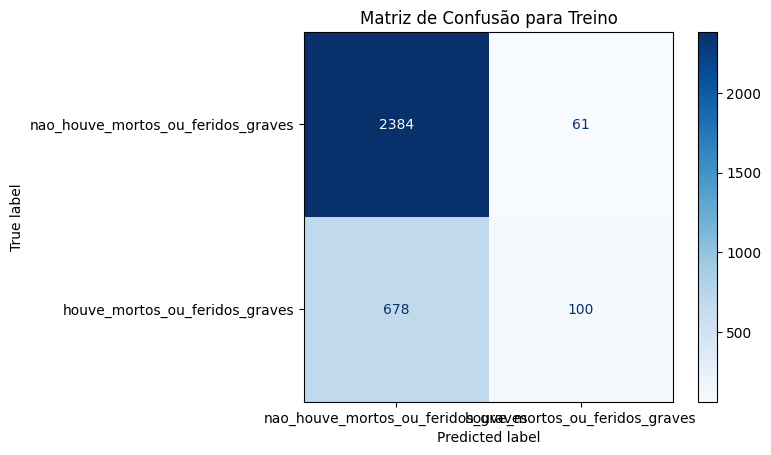

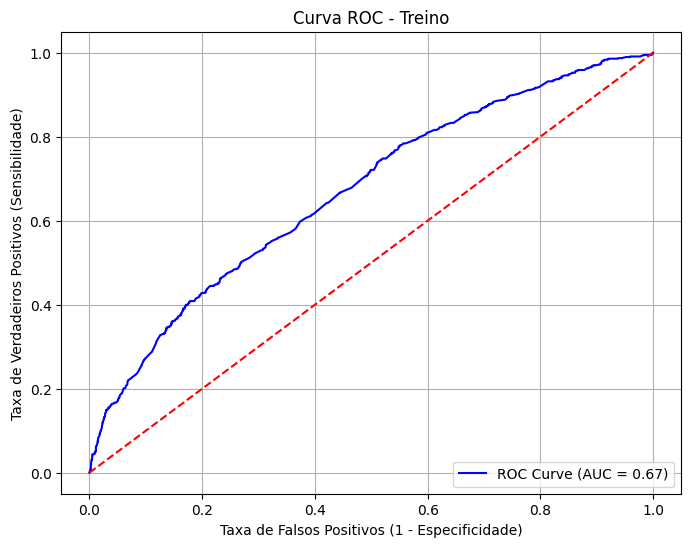

Métricas e Matriz de Confusão para OOT
Acurácia: 0.77
Sensibilidade: 0.13
Especificidade: 0.98
F1: 0.21
Precisão: 0.67
AUC: 0.68
Ponto de Corte Fixo: 0.50


<Figure size 1000x800 with 0 Axes>

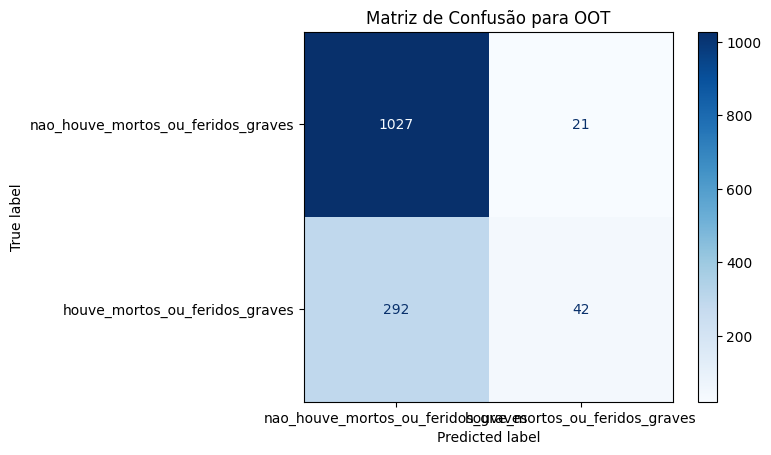

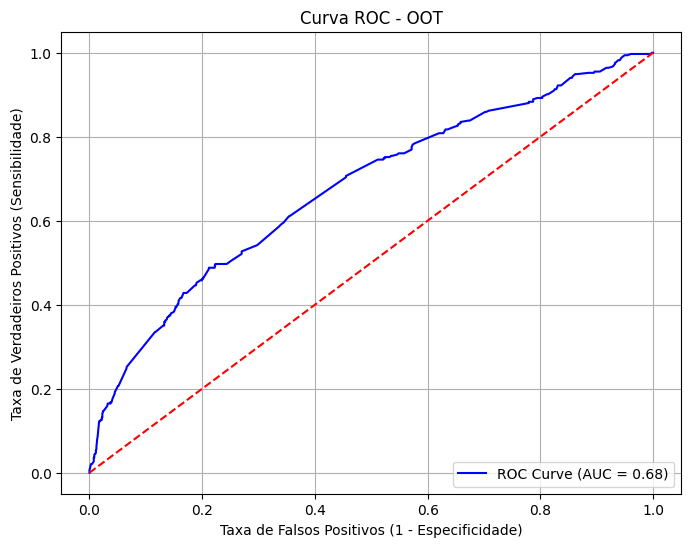

In [ ]:
#REGRESSAO LOGISTICA, PORÉM SEM AJUSTE NO PONTO DE CORTE , MAS COM StratifiedKFold

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Definir o ponto de corte fixo
fixed_threshold = 0.5

# Função para exibir a matriz de confusão
def plot_confusion_matrix(y_true, y_pred=None, X=None, modelo=None, title='Matriz de Confusão'):
    if modelo:
        y_probs = modelo.predict_proba(X)[:, 1]
        y_pred_optimal = (y_probs >= fixed_threshold).astype(int)
    else:
        y_pred_optimal = y_pred

    conf_matrix = confusion_matrix(y_true, y_pred_optimal)

    plt.figure(figsize=(10, 8))  # Ajuste o tamanho da figura conforme necessário
    disp = ConfusionMatrixDisplay(conf_matrix, display_labels=['nao_houve_mortos_ou_feridos_graves', 'houve_mortos_ou_feridos_graves'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()

# Função para plotar a curva ROC
def plot_roc_curve(y_true, y_probs, title="Curva ROC"):
    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    auc_score = roc_auc_score(y_true, y_probs)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--')  # Linha de referência
    plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
    plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

# Função para exibir as métricas, incluindo a AUC
def exibir_metricas(y_true, y_pred, y_probs):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    f1 = f1_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    auc_score = roc_auc_score(y_true, y_probs)

    print(f'Acurácia: {accuracy:.2f}')
    print(f'Sensibilidade: {sensitivity:.2f}')
    print(f'Especificidade: {specificity:.2f}')
    print(f'F1: {f1:.2f}')
    print(f'Precisão: {precision:.2f}')
    print(f'AUC: {auc_score:.2f}')  # Adiciona o AUC
    print(f'Ponto de Corte Fixo: {fixed_threshold:.2f}')

# Definir o pipeline para Logistic Regression
pipeline = Pipeline(steps=steps_em_comum + steps_exclusivos_lineares + [('logistic_regression', LogisticRegression(random_state=random_state))])

# Configurar validação cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

# Usar cross_val_predict para obter previsões de probabilidade
y_probs_train = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

# Ajustar previsões com o ponto de corte fixo
y_pred_train_optimal = (y_probs_train >= fixed_threshold).astype(int)

# Ajustar o modelo com o conjunto de treino completo
pipeline.fit(X_train, y_train)

# Prever probabilidades para o conjunto OOT
y_probs_oot = pipeline.predict_proba(X_oot)[:, 1]
y_pred_oot_optimal = (y_probs_oot >= fixed_threshold).astype(int)

# Exibir métricas e matriz de confusão para treino e OOT
print("Métricas e Matriz de Confusão para o Treino")
exibir_metricas(y_train, y_pred_train_optimal, y_probs_train)
plot_confusion_matrix(y_train, y_pred=y_pred_train_optimal, X=X_train, modelo=pipeline, title='Matriz de Confusão para Treino')

# Plotar a curva ROC para o conjunto de treino
plot_roc_curve(y_train, y_probs_train, title="Curva ROC - Treino")

print("Métricas e Matriz de Confusão para OOT")
exibir_metricas(y_oot, y_pred_oot_optimal, y_probs_oot)
plot_confusion_matrix(y_oot, y_pred=y_pred_oot_optimal, X=X_oot, modelo=pipeline, title='Matriz de Confusão para OOT')

# Plotar a curva ROC para o conjunto OOT
plot_roc_curve(y_oot, y_probs_oot, title="Curva ROC - OOT")



Métricas, Matriz de Confusão e Curva ROC para o Treino
Acurácia: 0.69
Sensibilidade: 0.46
Especificidade: 0.77
F1: 0.42
Precisão: 0.39
AUC: 0.67
Best threshold: 0.25


<Figure size 1000x800 with 0 Axes>

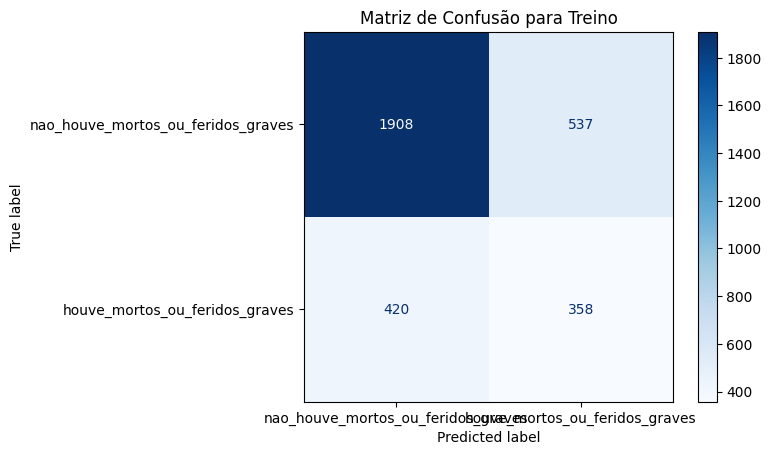

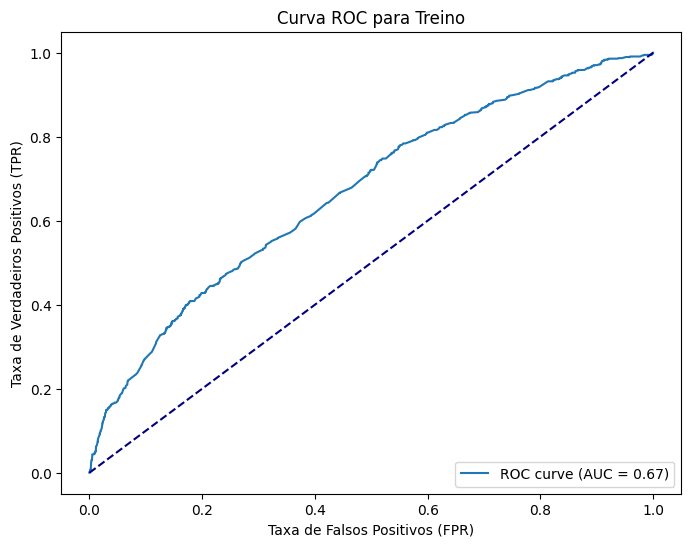

Métricas, Matriz de Confusão e Curva ROC para OOT
Acurácia: 0.70
Sensibilidade: 0.50
Especificidade: 0.77
F1: 0.45
Precisão: 0.41
AUC: 0.68
Best threshold: 0.25


<Figure size 1000x800 with 0 Axes>

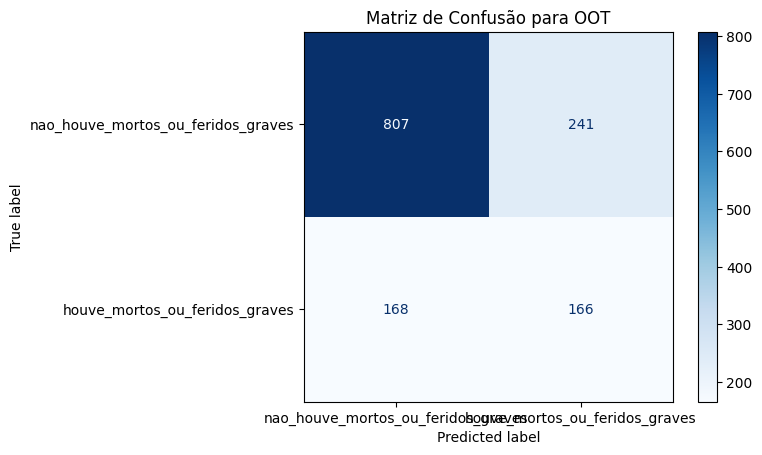

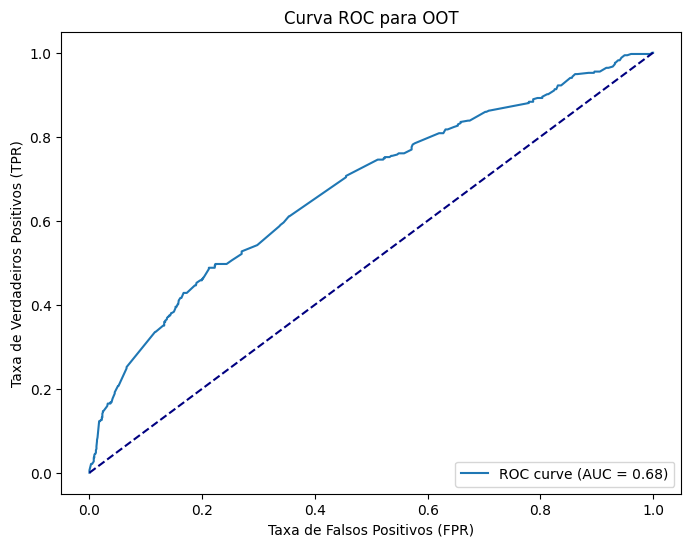

In [ ]:
#REGRESSAO LOGISTICA, PORÉM COM AJUSTE NO PONTO DE CORTE (QUE MAXIMIZA A SENSIBILIDADE E ESPECIFICIDADE), MAS COM StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Função para encontrar o melhor ponto de corte
def optimal_threshold(y_true, y_probs):
    thresholds = [i / 100.0 for i in range(101)]
    best_threshold = 0
    best_sens = 0
    best_spec = 0

    for threshold in thresholds:
        y_pred = (y_probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)

        # Escolher o ponto de corte que maximiza a sensibilidade e especificidade
        if sensitivity + specificity > best_sens + best_spec:
            best_sens = sensitivity
            best_spec = specificity
            best_threshold = threshold

    return best_threshold

# Função para exibir a matriz de confusão
def plot_confusion_matrix(y_true, y_pred=None, X=None, modelo=None, title='Matriz de Confusão'):
    if modelo:
        y_probs = modelo.predict_proba(X)[:, 1]
        y_pred_optimal = (y_probs >= best_threshold).astype(int)
    else:
        y_pred_optimal = y_pred

    conf_matrix = confusion_matrix(y_true, y_pred_optimal)

    plt.figure(figsize=(10, 8))  # Ajuste o tamanho da figura conforme necessário
    disp = ConfusionMatrixDisplay(conf_matrix, display_labels=['nao_houve_mortos_ou_feridos_graves', 'houve_mortos_ou_feridos_graves'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()

# Função para exibir as métricas
def exibir_metricas(y_true, y_pred, y_probs):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    f1 = f1_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    auc_score = roc_auc_score(y_true, y_probs)

    print(f'Acurácia: {accuracy:.2f}')
    print(f'Sensibilidade: {sensitivity:.2f}')
    print(f'Especificidade: {specificity:.2f}')
    print(f'F1: {f1:.2f}')
    print(f'Precisão: {precision:.2f}')
    print(f'AUC: {auc_score:.2f}')
    print(f'Best threshold: {best_threshold:.2f}')

# Função para plotar a curva ROC
def plot_roc_curve(y_true, y_probs, title='Curva ROC'):
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    auc_score = roc_auc_score(y_true, y_probs)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()

# Definir o pipeline para Logistic Regression
pipeline = Pipeline(steps=steps_em_comum + steps_exclusivos_lineares + [('logistic_regression', LogisticRegression(random_state=random_state))])

# Configurar validação cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

# Usar cross_val_predict para obter previsões de probabilidade
y_probs_train = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

# Encontrar o melhor ponto de corte usando todas as previsões de probabilidade
best_threshold = optimal_threshold(y_train, y_probs_train)

# Ajustar previsões com o ponto de corte otimizado
y_pred_train_optimal = (y_probs_train >= best_threshold).astype(int)

# Ajustar o modelo com o conjunto de treino completo
pipeline.fit(X_train, y_train)

# Prever probabilidades para o conjunto OOT
y_probs_oot = pipeline.predict_proba(X_oot)[:, 1]
y_pred_oot_optimal = (y_probs_oot >= best_threshold).astype(int)

# Exibir métricas, matriz de confusão e curva ROC para treino
print("Métricas, Matriz de Confusão e Curva ROC para o Treino")
exibir_metricas(y_train, y_pred_train_optimal, y_probs_train)
plot_confusion_matrix(y_train, y_pred=y_pred_train_optimal, X=X_train, modelo=pipeline, title='Matriz de Confusão para Treino')
plot_roc_curve(y_train, y_probs_train, title='Curva ROC para Treino')

# Exibir métricas, matriz de confusão e curva ROC para OOT
print("Métricas, Matriz de Confusão e Curva ROC para OOT")
exibir_metricas(y_oot, y_pred_oot_optimal, y_probs_oot)
plot_confusion_matrix(y_oot, y_pred=y_pred_oot_optimal, X=X_oot, modelo=pipeline, title='Matriz de Confusão para OOT')
plot_roc_curve(y_oot, y_probs_oot, title='Curva ROC para OOT')



#### Modelo 1:  Machine Learning Regressão Logística ajuste ponto de corte
##### (Maximiza Sensibilidade e mantem o minimo aceitavel de especificidade e acuracia)

Métricas e Matriz de Confusão para o Treino
Acurácia: 0.55
Sensibilidade: 0.72
Especificidade: 0.50
Precisão: 0.31
F1: 0.44
ROC AUC: 0.67
Best threshold: 0.21


<Figure size 1000x800 with 0 Axes>

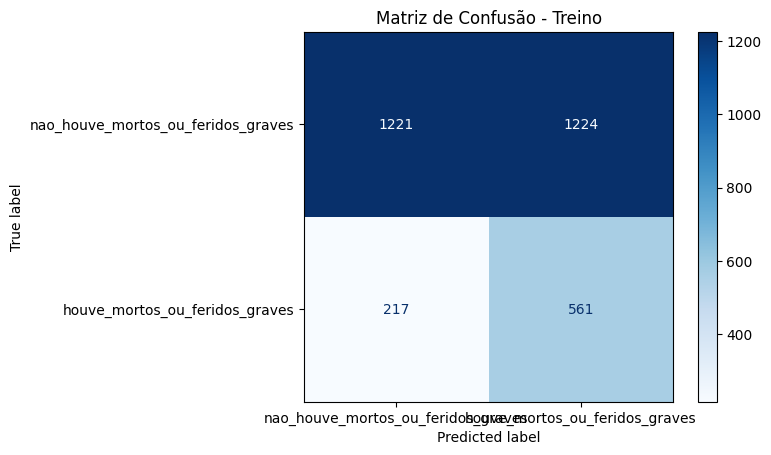

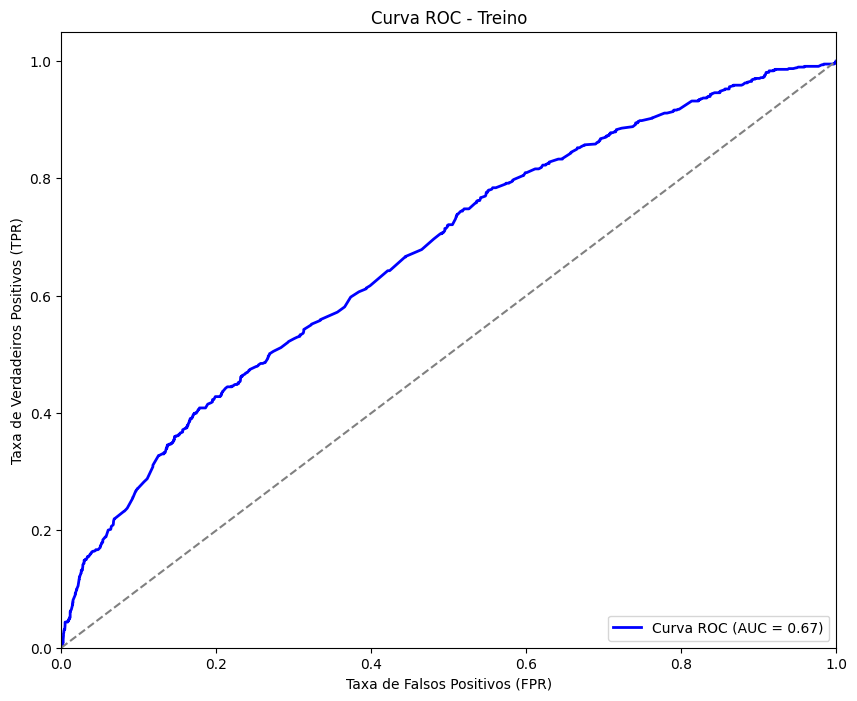

Métricas e Matriz de Confusão para OOT
Acurácia: 0.55
Sensibilidade: 0.75
Especificidade: 0.49
Precisão: 0.32
F1: 0.44
ROC AUC: 0.68
Best threshold: 0.21


<Figure size 1000x800 with 0 Axes>

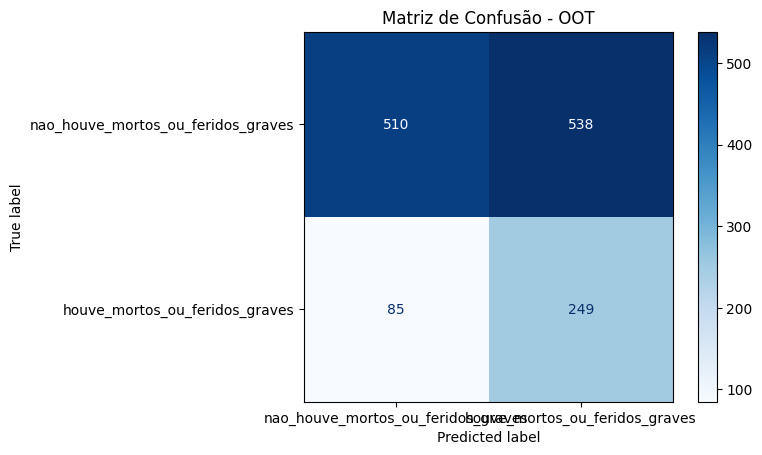

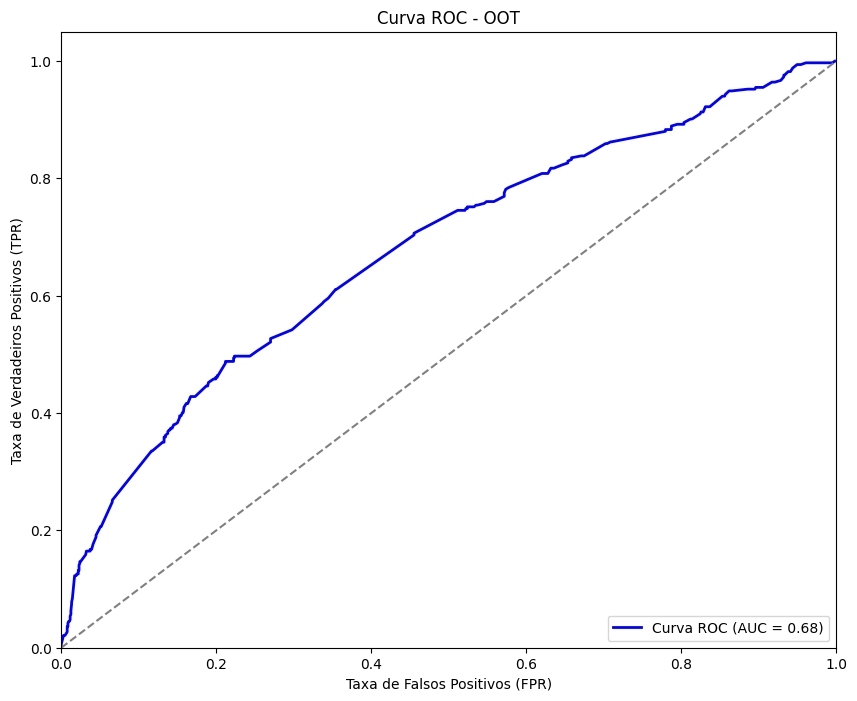

In [ ]:
#REGRESSAO LOGISTICA, PORÉM COM AJUSTE NO PONTO DE CORTE (QUE MAXIMIZA A SENSIBILIDADE E MANTEM O MINIMO SATISFATORIO DA ESPECIFICIDADE E ACURACIA), MAS COM StratifiedKFold

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, f1_score, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Função para encontrar o melhor ponto de corte
def optimal_threshold(y_true, y_probs, min_spec=0.49, min_accuracy=0.55):
    thresholds = [i / 100.0 for i in range(101)]
    best_threshold = 0
    best_sens = 0
    best_spec = 0
    best_accuracy = 0

    for threshold in thresholds:
        y_pred = (y_probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)
        accuracy = accuracy_score(y_true, y_pred)

        # Verificar se a sensibilidade é maximizada e a especificidade e acurácia são minimamente aceitáveis
        if sensitivity > best_sens and specificity >= min_spec and accuracy >= min_accuracy:
            best_sens = sensitivity
            best_spec = specificity
            best_accuracy = accuracy
            best_threshold = threshold

    return best_threshold

# Função para exibir a matriz de confusão
def plot_confusion_matrix(y_true, y_pred, title='Matriz de Confusão'):
    conf_matrix = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))  # Ajuste o tamanho da figura conforme necessário
    disp = ConfusionMatrixDisplay(conf_matrix, display_labels=['nao_houve_mortos_ou_feridos_graves', 'houve_mortos_ou_feridos_graves'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()

# Função para exibir a curva ROC
def plot_roc_curve(y_true, y_probs, title='Curva ROC'):
    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    roc_auc = roc_auc_score(y_true, y_probs)

    plt.figure(figsize=(10, 8))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.show()

# Função para exibir as métricas
def exibir_metricas(y_true, y_pred, y_probs):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = precision_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_probs)  # AUC baseado nas probabilidades

    print(f'Acurácia: {accuracy:.2f}')
    print(f'Sensibilidade: {sensitivity:.2f}')
    print(f'Especificidade: {specificity:.2f}')
    print(f'Precisão: {precision:.2f}')
    print(f'F1: {f1:.2f}')
    print(f'ROC AUC: {roc_auc:.2f}')
    print(f'Best threshold: {best_threshold:.2f}')

# Definir o pipeline para Logistic Regression
pipeline = Pipeline(steps=steps_em_comum + steps_exclusivos_lineares + [('logistic_regression', LogisticRegression(random_state=random_state))])

# Configurar validação cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

# Usar cross_val_predict para obter previsões de probabilidade
y_probs_train = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

# Encontrar o melhor ponto de corte usando todas as previsões de probabilidade
best_threshold = optimal_threshold(y_train, y_probs_train)

# Ajustar previsões com o melhor ponto de corte
y_pred_train_optimal = (y_probs_train >= best_threshold).astype(int)

# Ajustar o modelo com o conjunto de treino completo
pipeline.fit(X_train, y_train)

# Prever probabilidades para o conjunto OOT
y_probs_oot = pipeline.predict_proba(X_oot)[:, 1]
y_pred_oot_optimal = (y_probs_oot >= best_threshold).astype(int)

# Exibir métricas e matriz de confusão para treino e OOT
print("Métricas e Matriz de Confusão para o Treino")
exibir_metricas(y_train, y_pred_train_optimal, y_probs_train)
plot_confusion_matrix(y_train, y_pred_train_optimal, title='Matriz de Confusão - Treino')
plot_roc_curve(y_train, y_probs_train, title='Curva ROC - Treino')

print("Métricas e Matriz de Confusão para OOT")
exibir_metricas(y_oot, y_pred_oot_optimal, y_probs_oot)
plot_confusion_matrix(y_oot, y_pred_oot_optimal, title='Matriz de Confusão - OOT')
plot_roc_curve(y_oot, y_probs_oot, title='Curva ROC - OOT')


#### Modelo 2 - Machine Learning Regressão Logística - Modelo Otimizado

##### Treinando o melhor modelo otimizado, mantendo o ajuste no ponto de corte


In [ ]:
def calcular_custo_prevencao(y_true, y_pred):
    custo_acidente = 2600  # Custo médio por acidente grave
    custo_reparo_fn = 3000  # Custo adicional para remediar falsos negativos (FN)
    custo_prevencao_fp = 400  # Custo da mobilização preventiva em falsos positivos (FP), porém aqui é prevenção!

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    # Cálculo de custos
    custo_tp = tp * custo_acidente
    custo_fn = fn * (custo_reparo_fn)
    custo_fp = fp * custo_prevencao_fp

    custo_sem_modelo = ((tp+fn)*custo_acidente)
    custo_com_modelo = (custo_tp + custo_fn + custo_fp)
    economia_efetiva = custo_sem_modelo - custo_com_modelo

    return custo_sem_modelo,custo_com_modelo, economia_efetiva, tp, fn, fp, tn

Fitting 5 folds for each of 84 candidates, totalling 420 fits


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_search.py:320: UserWarning: The total space of parameters 84 is smaller than n_iter=100. Running 84 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
280 fits failed out of a total of 420.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
72 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1473, 

Best Parameters: {'logit__penalty': 'l2', 'logit__fit_intercept': True, 'logit__class_weight': 'balanced', 'logit__C': 100}
Best Score: 0.6727162081931526
Best Threshold: 0.47


<Figure size 800x600 with 0 Axes>

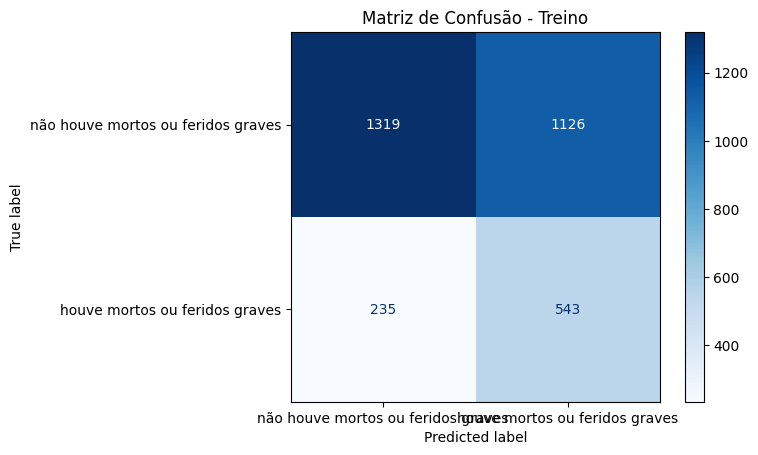


Métricas para Matriz de Confusão - Treino:
Acurácia: 0.58
Sensibilidade: 0.70
Especificidade: 0.54
Precisão: 0.33
Acurácia Balanceada: 0.62
F1 Score: 0.44
ROC AUC: 0.68
Best threshold: 0.47


<Figure size 800x600 with 0 Axes>

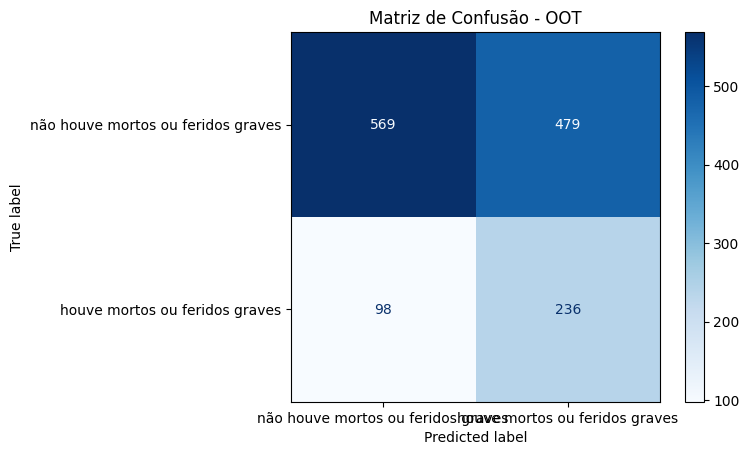


Métricas para Matriz de Confusão - OOT:
Acurácia: 0.58
Sensibilidade: 0.71
Especificidade: 0.54
Precisão: 0.33
Acurácia Balanceada: 0.62
F1 Score: 0.45
ROC AUC: 0.68
Best threshold: 0.47
Custo sem Modelo - Treino: 2022800
Custo com Modelo - Treino: 2567200
Economia Efetiva - Treino: -544400
Custo sem Modelo - OOT: 868400
Custo com Modelo - OOT: 1099200
Economia Efetiva - OOT: -230800


In [ ]:
#APLICANDO O RANDOMIZED NO MELHOR MODELO, PARA IDENTIFICAR OS MELHORES PARAMETROS.
#LEMBRANDO QUE ESTOU USANDO O CONCEITO DO PONTO DE CORTE QUE MAXIMIZA A SENSIBILIDADE E CONSIERA O MINIMO ACEITAVEL DE ACURACIA E ESPECIFICIDADE
#E ESTOU CONSIDERANDO REGRESSAO LOGISTICA COM APENAS AS VARIAVEIS RELEVANTES
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from feature_engine.wrappers import SklearnTransformerWrapper
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, balanced_accuracy_score, precision_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt

# Ajustar o pipeline para incluir o escalonador
melhor_modelo = Pipeline(steps=steps_em_comum + steps_exclusivos_lineares + [('logit', LogisticRegression(random_state=random_state))])

# Parâmetros para RandomizedSearchCV
parameters = {
    'logit__penalty': ['none', 'l2', 'l1'],
    'logit__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'logit__class_weight': ['balanced', None],
    'logit__fit_intercept': [True, False]
}

# Configurar StratifiedKFold
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Configurar RandomizedSearchCV com StratifiedKFold
melhor_modelo_otimizado = RandomizedSearchCV(
    melhor_modelo,
    parameters,
    scoring='roc_auc',
    cv=stratified_kfold,
    n_iter=100,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Ajustar o modelo
melhor_modelo_otimizado.fit(X_train, y_train)

# Exibir o melhor modelo e seus parâmetros
print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')
print(f'Best Score: {melhor_modelo_otimizado.best_score_}')


# Encontrar o melhor ponto de corte
def optimal_threshold(y_true, y_probs, min_spec=0.50, min_acc=0.55):
    thresholds = [i / 100.0 for i in range(101)]
    best_threshold = 0
    best_sens = 0
    best_spec = 0

    for threshold in thresholds:
        y_pred = (y_probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)
        accuracy = accuracy_score(y_true, y_pred)

        # Escolher o ponto de corte que maximiza a sensibilidade e atende os limites de especificidade e acurácia
        if sensitivity > best_sens and specificity >= min_spec and accuracy >= min_acc:
            best_sens = sensitivity
            best_spec = specificity
            best_threshold = threshold

    return best_threshold

# Função para exibir a matriz de confusão e métricas
def plot_confusion_matrix_and_metrics(y_true, X, modelo, best_threshold, title='Matriz de Confusão'):
    y_probs = modelo.predict_proba(X)[:, 1]
    y_pred_optimal = (y_probs >= best_threshold).astype(int)
    conf_matrix = confusion_matrix(y_true, y_pred_optimal)

    # Plotar a matriz de confusão
    plt.figure(figsize=(8, 6))  # Ajuste o tamanho da figura conforme necessário
    disp = ConfusionMatrixDisplay(conf_matrix, display_labels=['não houve mortos ou feridos graves', 'houve mortos ou feridos graves'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()

    # Calcular e exibir métricas
    print(f"\nMétricas para {title}:")
    tn, fp, fn, tp = conf_matrix.ravel()
    accuracy = accuracy_score(y_true, y_pred_optimal)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = precision_score(y_true, y_pred_optimal)
    balanced_acc = balanced_accuracy_score(y_true, y_pred_optimal)
    f1 = f1_score(y_true, y_pred_optimal)
    roc_auc = roc_auc_score(y_true, y_probs)

    print(f"Acurácia: {accuracy:.2f}")
    print(f"Sensibilidade: {sensitivity:.2f}")
    print(f"Especificidade: {specificity:.2f}")
    print(f"Precisão: {precision:.2f}")
    print(f"Acurácia Balanceada: {balanced_acc:.2f}")
    print(f"F1 Score: {f1:.2f}")
    print(f"ROC AUC: {roc_auc:.2f}")
    print(f'Best threshold: {best_threshold:.2f}')

# Prever probabilidades para o conjunto de treino
y_probs_train = melhor_modelo_otimizado.predict_proba(X_train)[:, 1]
# Encontrar o melhor ponto de corte com prioridade para sensibilidade
best_threshold = optimal_threshold(y_train, y_probs_train, min_spec=0.50, min_acc=0.55)

print(f'Best Threshold: {best_threshold}')

# Avaliar o modelo otimizado
def evaluate_model(model, X_train, y_train, X_oot, y_oot, best_threshold):
    # Prever probabilidades para todos os conjuntos de dados
    y_probs_train = model.predict_proba(X_train)[:, 1]
    y_probs_oot = model.predict_proba(X_oot)[:, 1]

    # Ajustar previsões com o melhor ponto de corte
    y_pred_train_optimal = (y_probs_train >= best_threshold).astype(int)
    y_pred_oot_optimal = (y_probs_oot >= best_threshold).astype(int)

    # Exibir a matriz de confusão e métricas para treino, teste e OOT
    plot_confusion_matrix_and_metrics(y_train, X_train, model, best_threshold, title='Matriz de Confusão - Treino')
    plot_confusion_matrix_and_metrics(y_oot, X_oot, model, best_threshold, title='Matriz de Confusão - OOT')

# Avaliar o modelo otimizado
evaluate_model(melhor_modelo_otimizado, X_train, y_train, X_oot, y_oot, best_threshold)

# Calcular custos usando a função do código 2
# Prever as classes com o melhor ponto de corte
y_pred_train_optimal = (melhor_modelo_otimizado.predict_proba(X_train)[:, 1] >= best_threshold).astype(int)
y_pred_oot_optimal = (melhor_modelo_otimizado.predict_proba(X_oot)[:, 1] >= best_threshold).astype(int)


# Chamar a função calcular_custo_prevencao
custo_train, custo_com_modelo_train, economia_efetiva_train, tp_train, fn_train, fp_train, tn_train = calcular_custo_prevencao(y_train, y_pred_train_optimal)
custo_oot, custo_com_modelo_oot, economia_efetiva_oot, tp_oot, fn_oot, fp_oot, tn_oot = calcular_custo_prevencao(y_oot, y_pred_oot_optimal)

# Exibir os resultados de custo_prevencao
print(f"Custo sem Modelo - Treino: {custo_train}")
print(f"Custo com Modelo - Treino: {custo_com_modelo_train}")
print(f"Economia Efetiva - Treino: {economia_efetiva_train}")

print(f"Custo sem Modelo - OOT: {custo_oot}")
print(f"Custo com Modelo - OOT: {custo_com_modelo_oot}")
print(f"Economia Efetiva - OOT: {economia_efetiva_oot}")


In [ ]:
# Parâmetros ótimizados do melhor modelo
print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')


Best Parameters: {'logit__penalty': 'l2', 'logit__fit_intercept': True, 'logit__class_weight': 'balanced', 'logit__C': 100}


In [ ]:
# Listar todos os passos do pipeline para verificar o pré-processador
print("Passos do pipeline:")
for step_name, step_process in melhor_modelo_otimizado.best_estimator_.named_steps.items():
    print(f"{step_name}: {step_process}")



Passos do pipeline:
numeric_imputer: MeanMedianImputer(variables=['pessoas', 'veiculos'])
categoric_imputer: CategoricalImputer(variables=['tipo_pista', 'causa_acidente_agg',
                              'tipo_acidente_categ'])
one_hot_encoder: OneHotEncoder(variables=['tipo_pista', 'causa_acidente_agg',
                         'tipo_acidente_categ'])
numeric_scaler: SklearnTransformerWrapper(transformer=StandardScaler(),
                          variables=['pessoas', 'veiculos'])
logit: LogisticRegression(C=100, class_weight='balanced', random_state=42)


In [ ]:
# Verifique se o ajuste foi feito corretamente
if hasattr(melhor_modelo_otimizado, 'best_estimator_'):
    model = melhor_modelo_otimizado.best_estimator_.named_steps['logit']
else:
    print("O ajuste do modelo não foi realizado corretamente.")


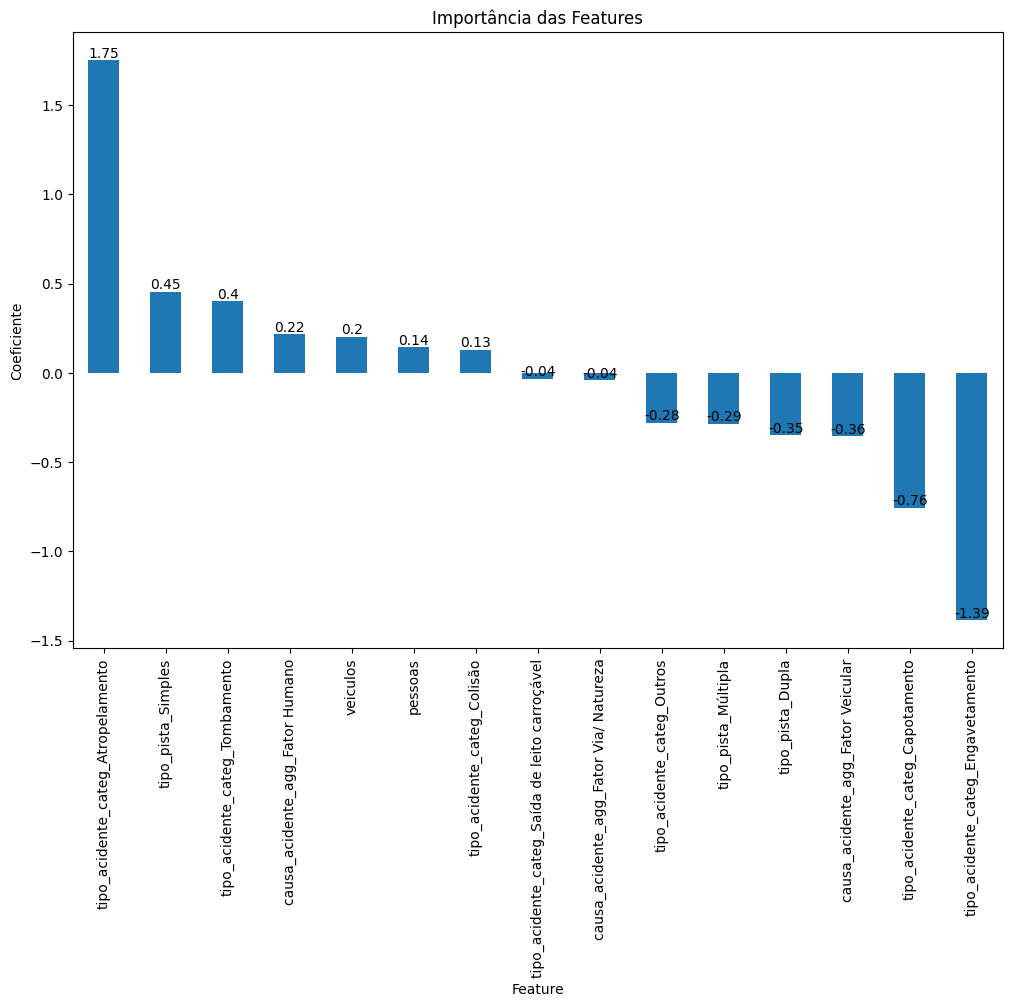

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Verificar se o ajuste foi feito corretamente
if hasattr(melhor_modelo_otimizado, 'best_estimator_'):
    # Extrair o modelo ajustado
    model = melhor_modelo_otimizado.best_estimator_.named_steps['logit']

    # Obter coeficientes e nomes das features
    coef = model.coef_[0]
    feature_names = melhor_modelo_otimizado.best_estimator_.named_steps['one_hot_encoder'].get_feature_names_out()

    # Adicionar os nomes das variáveis numéricas
    feature_names = list(feature_names)
    # Verificar se o número de coeficientes corresponde ao número de features
    if len(coef) == len(feature_names):
        # Criar uma série com os coeficientes e os nomes das features
        feature_importance = pd.Series(coef, index=feature_names).sort_values(ascending=False)

        # Plotar as importâncias das features
        plt.figure(figsize=(12, 8))
        bars = feature_importance.plot(kind='bar')

        # Adicionar rótulos aos valores
        for bar in bars.patches:
            yval = bar.get_height()
            plt.text(bar.get_x() + bar.get_width() / 2, yval, round(yval, 2), ha='center', va='bottom')

        plt.title('Importância das Features')
        plt.xlabel('Feature')
        plt.ylabel('Coeficiente')
        plt.show()
    else:
        print(f"Descompasso detectado: {len(coef)} coeficientes, {len(feature_names)} nomes de features.")
else:
    print("O ajuste do modelo não foi realizado corretamente.")


#### Modelo 3 - Machine Learning Cat Boost

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Parameters: {'catboost__learning_rate': 0.1, 'catboost__l2_leaf_reg': 5, 'catboost__iterations': 200, 'catboost__depth': 4, 'catboost__border_count': 64}
Best Score: 0.6815562642823675
Best Threshold: 0.21


<Figure size 800x600 with 0 Axes>

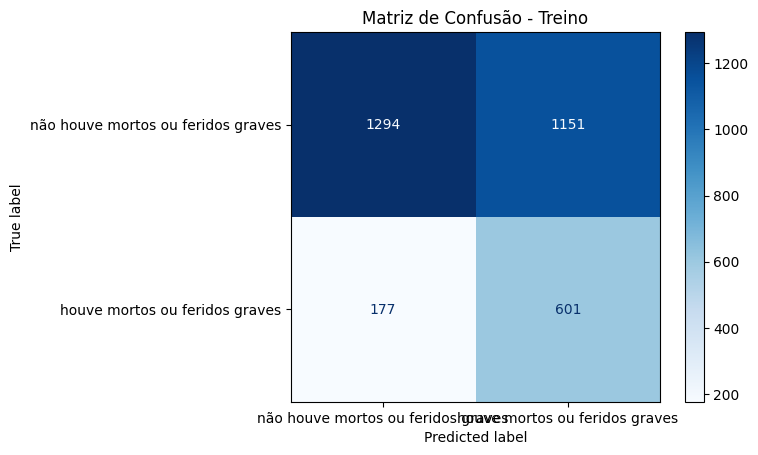


Métricas para Matriz de Confusão - Treino:
Acurácia: 0.59
Sensibilidade: 0.77
Especificidade: 0.53
Precisão: 0.34
Acurácia Balanceada: 0.65
F1 Score: 0.48
ROC AUC: 0.74
Best threshold: 0.21


<Figure size 800x600 with 0 Axes>

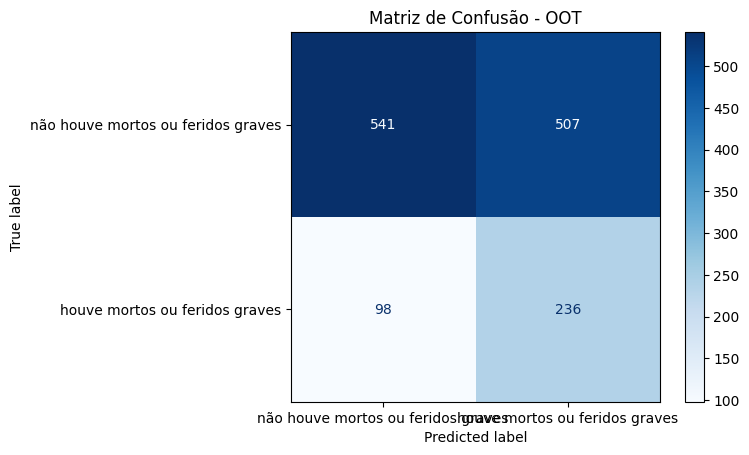


Métricas para Matriz de Confusão - OOT:
Acurácia: 0.56
Sensibilidade: 0.71
Especificidade: 0.52
Precisão: 0.32
Acurácia Balanceada: 0.61
F1 Score: 0.44
ROC AUC: 0.67
Best threshold: 0.21


In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, f1_score, roc_auc_score, balanced_accuracy_score
import matplotlib.pyplot as plt

# Ajustar o pipeline para incluir o escalonador e o modelo CatBoost
melhor_modelo = Pipeline(steps=steps_em_comum + [('catboost', CatBoostClassifier(random_state=random_state, silent=True))])

# Parâmetros para RandomizedSearchCV
parameters = {
    'catboost__depth': [4, 6, 8, 10],
    'catboost__learning_rate': [0.01, 0.05, 0.1, 0.3],
    'catboost__iterations': [100, 200, 500, 1000],
    'catboost__l2_leaf_reg': [1, 3, 5, 7, 9],
    'catboost__border_count': [32, 64, 128]
}


# Configurar StratifiedKFold
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Configurar RandomizedSearchCV com StratifiedKFold
melhor_modelo_otimizado = RandomizedSearchCV(
    melhor_modelo,
    parameters,
    scoring='roc_auc',
    cv=stratified_kfold,
    n_iter=100,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Ajustar o modelo
melhor_modelo_otimizado.fit(X_train, y_train)

# Exibir o melhor modelo e seus parâmetros
print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')
print(f'Best Score: {melhor_modelo_otimizado.best_score_}')

# Encontrar o melhor ponto de corte com prioridade para sensibilidade
best_threshold = optimal_threshold(y_train, melhor_modelo_otimizado.predict_proba(X_train)[:, 1], min_spec=0.50, min_acc=0.55)
print(f'Best Threshold: {best_threshold}')

# Avaliar o modelo otimizado
evaluate_model(melhor_modelo_otimizado, X_train, y_train, X_oot, y_oot, best_threshold)



In [ ]:
# Parâmetros ótimizados do melhor modelo
print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')

Best Parameters: {'catboost__learning_rate': 0.1, 'catboost__l2_leaf_reg': 5, 'catboost__iterations': 200, 'catboost__depth': 4, 'catboost__border_count': 64}


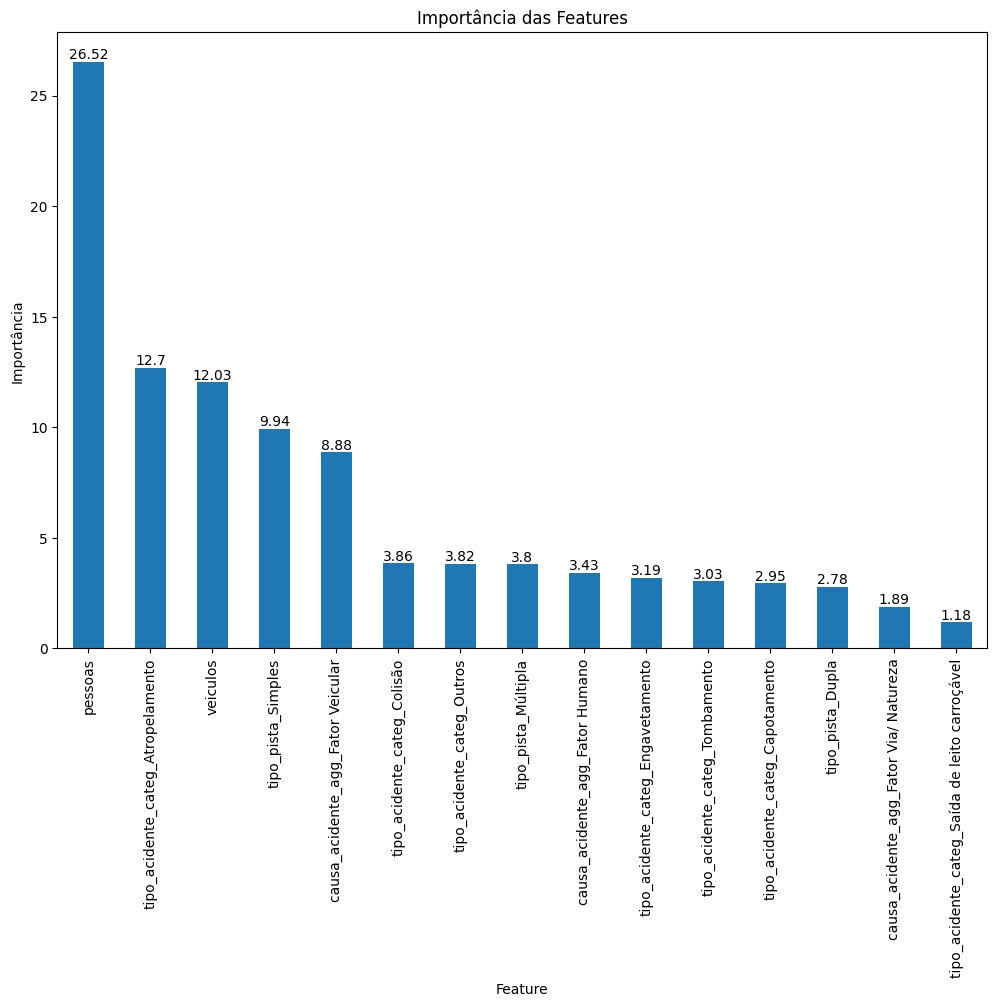

Best Parameters: {'catboost__learning_rate': 0.1, 'catboost__l2_leaf_reg': 5, 'catboost__iterations': 200, 'catboost__depth': 4, 'catboost__border_count': 64}


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Verificar se o ajuste foi feito corretamente
if hasattr(melhor_modelo_otimizado, 'best_estimator_'):
    # Extrair o modelo ajustado
    model = melhor_modelo_otimizado.best_estimator_.named_steps['catboost']

    # Obter importâncias das features
    importances = model.get_feature_importance()

    # Obter os nomes das features
    feature_names = melhor_modelo_otimizado.best_estimator_.named_steps['one_hot_encoder'].get_feature_names_out()

    # Criar uma série com as importâncias das features e os nomes das features
    feature_importance = pd.Series(importances, index=feature_names).sort_values(ascending=False)

    # Plotar as importâncias das features
    plt.figure(figsize=(12, 8))
    bars = feature_importance.plot(kind='bar')

    # Adicionar rótulos aos valores
    for bar in bars.patches:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, yval, round(yval, 2), ha='center', va='bottom')

    plt.title('Importância das Features')
    plt.xlabel('Feature')
    plt.ylabel('Importância')
    plt.show()

    # Exibir os melhores parâmetros do modelo
    print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')
else:
    print("O ajuste do modelo não foi realizado corretamente.")


#### Modelo 4 - Machine Learning XGBoost

---



Fitting 5 folds for each of 100 candidates, totalling 500 fits


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:158: UserWarning: [14:37:23] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best Parameters: {'xgb__subsample': 1.0, 'xgb__scale_pos_weight': 5, 'xgb__reg_lambda': 5, 'xgb__n_estimators': 200, 'xgb__max_depth': 7, 'xgb__learning_rate': 0.01, 'xgb__gamma': 0.5, 'xgb__colsample_bytree': 0.6}
Best Score: 0.6799333813711412
Best Threshold: 0.58


<Figure size 800x600 with 0 Axes>

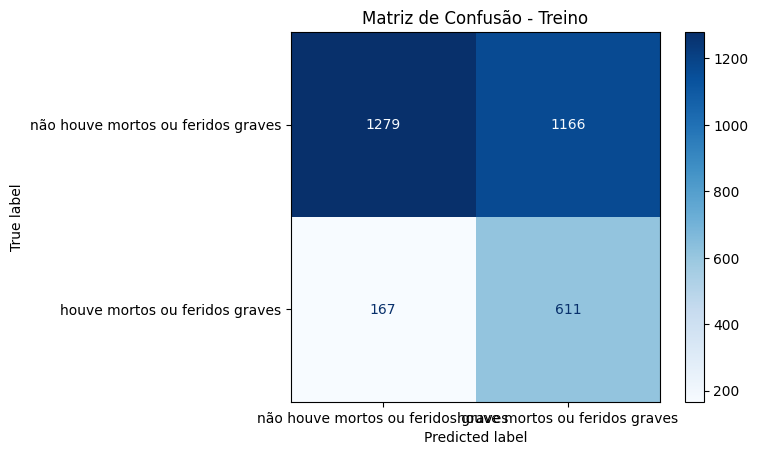


Métricas para Matriz de Confusão - Treino:
Acurácia: 0.59
Sensibilidade: 0.79
Especificidade: 0.52
Precisão: 0.34
Acurácia Balanceada: 0.65
F1 Score: 0.48
ROC AUC: 0.73
Best threshold: 0.58


<Figure size 800x600 with 0 Axes>

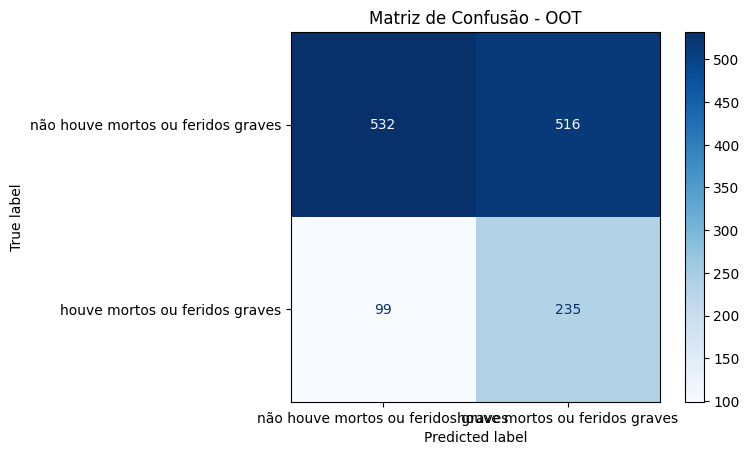


Métricas para Matriz de Confusão - OOT:
Acurácia: 0.55
Sensibilidade: 0.70
Especificidade: 0.51
Precisão: 0.31
Acurácia Balanceada: 0.61
F1 Score: 0.43
ROC AUC: 0.67
Best threshold: 0.58


In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, f1_score, roc_auc_score, balanced_accuracy_score
import matplotlib.pyplot as plt

# Ajustar o pipeline para incluir o escalonador e o modelo XGBoost
melhor_modelo = Pipeline(steps=steps_em_comum + [('xgb', XGBClassifier(random_state=random_state, use_label_encoder=False, eval_metric='logloss'))])

# Parâmetros para RandomizedSearchCV
parameters = {
    'xgb__n_estimators': [100, 200, 500, 1000],
    'xgb__max_depth': [3, 5, 7, 10],
    'xgb__learning_rate': [0.01, 0.05, 0.1, 0.3],
    'xgb__subsample': [0.6, 0.8, 1.0],
    'xgb__colsample_bytree': [0.6, 0.8, 1.0],
    'xgb__gamma': [0, 0.1, 0.3, 0.5],
    'xgb__reg_lambda': [0, 1, 3, 5],
    'xgb__scale_pos_weight': [1, 3, 5, 7]
}


# Configurar StratifiedKFold
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Configurar RandomizedSearchCV com StratifiedKFold
melhor_modelo_otimizado = RandomizedSearchCV(
    melhor_modelo,
    parameters,
    scoring='roc_auc',
    cv=stratified_kfold,
    n_iter=100,
    n_jobs=-1,
    verbose=1,
    random_state=42
)


# Ajustar o modelo
melhor_modelo_otimizado.fit(X_train, y_train)

# Exibir o melhor modelo e seus parâmetros
print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')
print(f'Best Score: {melhor_modelo_otimizado.best_score_}')

# Encontrar o melhor ponto de corte com prioridade para sensibilidade
best_threshold = optimal_threshold(y_train, melhor_modelo_otimizado.predict_proba(X_train)[:, 1], min_spec=0.50, min_acc=0.55)
print(f'Best Threshold: {best_threshold}')

# Avaliar o modelo otimizado
evaluate_model(melhor_modelo_otimizado, X_train, y_train, X_oot, y_oot, best_threshold)


In [ ]:
# Parâmetros ótimizados do melhor modelo
print(f'Best Parameters: {melhor_modelo_otimizado.best_params_}')

Best Parameters: {'xgb__subsample': 1.0, 'xgb__scale_pos_weight': 5, 'xgb__reg_lambda': 5, 'xgb__n_estimators': 200, 'xgb__max_depth': 7, 'xgb__learning_rate': 0.01, 'xgb__gamma': 0.5, 'xgb__colsample_bytree': 0.6}


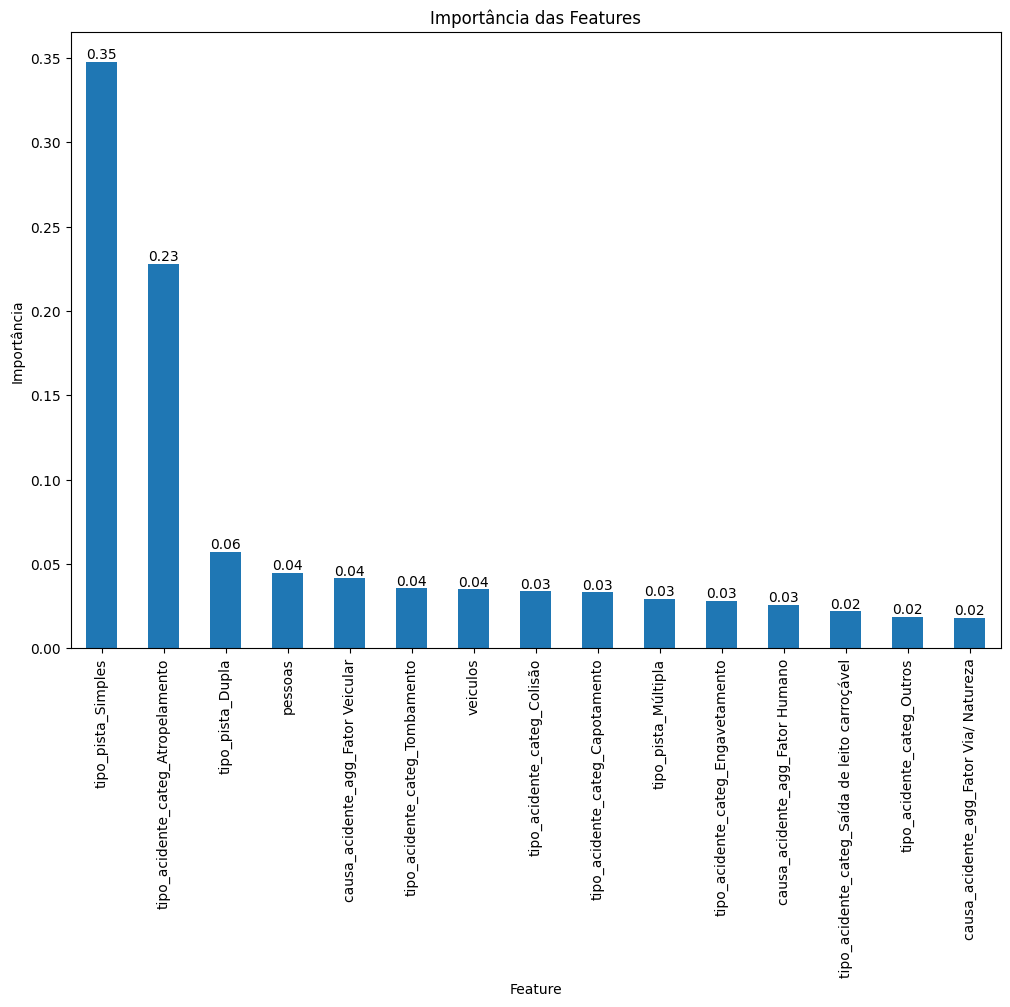

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Verificar se o ajuste foi feito corretamente
if hasattr(melhor_modelo_otimizado, 'best_estimator_'):
    # Extrair o modelo ajustado
    model = melhor_modelo_otimizado.best_estimator_.named_steps['xgb']

    # Obter importâncias das features
    importances = model.feature_importances_

    # Obter os nomes das features
    feature_names = melhor_modelo_otimizado.best_estimator_.named_steps['one_hot_encoder'].get_feature_names_out()

    # Criar uma série com as importâncias das features e os nomes das features
    feature_importance = pd.Series(importances, index=feature_names).sort_values(ascending=False)

    # Plotar as importâncias das features
    plt.figure(figsize=(12, 8))
    bars = feature_importance.plot(kind='bar')

    # Adicionar rótulos aos valores
    for bar in bars.patches:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, yval, round(yval, 2), ha='center', va='bottom')

    plt.title('Importância das Features')
    plt.xlabel('Feature')
    plt.ylabel('Importância')
    plt.show()
else:
    print("O ajuste do modelo não foi realizado corretamente.")


# 6. Deep Learning

In [ ]:
import pandas as pd

# Carregar os datasets
df_ocorrencia = pd.read_csv('../data/base_acidente_transito_MG_381_v2.csv')


# Verificar o período dos dados no dataset de pedidos
df_ocorrencia['data_inversa'] = pd.to_datetime(df_ocorrencia['data_inversa'])

df_ocorrencia['data_inversa'].agg(('min', 'max'))

,data_inversa
min,2022-01-01
max,2023-10-31


In [ ]:
df_abt = df_ocorrencia
df_abt.head(5)

,id,data_inversa,dia_semana,uf,br,sentido_via,condicao_metereologica,tipo_pista,tracado_via,pessoas,veiculos,ano_mes_ocorrencia,mes_ocorrencia,periodo_dia,Regiao,causa_acidente_agg,zona,houve_mortos_ou_feridos_graves,tipo_acidente_categ
0,405466,2022-01-02,domingo,MG,381,Crescente,Chuva,Dupla,Reta,1,1,2022-01,1,Tarde,Sudeste,Fator Humano,Rural,0,Saída de leito carroçável
1,405701,2022-01-03,segunda-feira,MG,381,Crescente,Nublado,Dupla,Reta,1,1,2022-01,1,Manhã,Sudeste,Fator Humano,Rural,0,Saída de leito carroçável
2,405820,2022-01-03,segunda-feira,MG,381,Crescente,Chuva,Simples,Curva,3,2,2022-01,1,Noite,Sudeste,Fator Via/ Natureza,Rural,0,Colisão
3,405940,2022-01-04,terça-feira,MG,381,Decrescente,Nublado,Simples,Curva,7,4,2022-01,1,Tarde,Sudeste,Fator Humano,Rural,1,Colisão
4,406053,2022-01-05,quarta-feira,MG,381,Crescente,Chuva,Dupla,NaN,6,2,2022-01,1,Manhã,Sudeste,Fator Humano,Rural,0,Colisão


In [ ]:
#SEPARANDO EM TREINO E OOT. SENDO QUE NO TREINO E TESTE A SEPARAÇÃO FOI DE 70% E 30%, E FOI CONSIDERADO O STRATIFY = Y, PARA MANTER A MESMA DISTRIBUICAO NAS BASES TREINO E TESTE
from sklearn.model_selection import train_test_split
import pandas as pd

# Supondo que df_abt já esteja carregado com os dados

# Base de treinamento e teste
df_train_oot = df_abt.query('data_inversa <= "2023-10-31"')


# Definição das variáveis
key_vars = ['uf', 'br', 'Regiao', 'id','data_inversa']
num_vars = ['pessoas', 'veiculos', 'mes_ocorrencia']
cat_vars = ['dia_semana','sentido_via','condicao_metereologica','tipo_pista','tracado_via','ano_mes_ocorrencia','periodo_dia','causa_acidente_agg','zona','tipo_acidente_categ']
target = 'houve_mortos_ou_feridos_graves'

features = cat_vars + num_vars

# Preparar X e y para o treino e teste
X_train_oot = df_train_oot[features]
y_train_oot = df_train_oot[target]

# Separar a base de treino e teste
X_train, X_oot, y_train, y_oot = train_test_split(
    X_train_oot, y_train_oot,
    train_size=0.7,
    stratify=y_train_oot,
    random_state=42  # Para garantir reprodutibilidade
)


# Verificar as formas dos DataFrames resultantes
print(f"Treinamento: {X_train.shape}, {y_train.shape}")
print(f"oot: {X_oot.shape}, {y_oot.shape}")



Treinamento: (3223, 13), (3223,)
oot: (1382, 13), (1382,)


In [ ]:
#PRÉ PROCESSAMENTO
from sklearn.pipeline import Pipeline

from feature_engine.imputation import MeanMedianImputer
from feature_engine.imputation import CategoricalImputer
from feature_engine.encoding import OneHotEncoder

from sklearn.preprocessing import StandardScaler
from feature_engine.wrappers import SklearnTransformerWrapper


# Pipeline de pré-processamento com feature-engine
data_pipeline = Pipeline(steps=[
    ('numeric_imputer', MeanMedianImputer(variables=num_vars, imputation_method='median')),
    ('categoric_imputer', CategoricalImputer(variables=cat_vars)),
    ('one_hot_encoder', OneHotEncoder(variables=cat_vars)),
    ('numeric_scaler', SklearnTransformerWrapper(variables=num_vars, transformer=StandardScaler()))
])

In [ ]:
X_train_transformed = data_pipeline.fit_transform(X_train)
X_oot_transformed = data_pipeline.transform(X_oot)

In [ ]:
X_train_transformed.shape

(3223, 70)

In [ ]:
X_oot_transformed.shape

(1382, 70)

#### Modelo 1 - Deep Learning Redes Densas

In [ ]:
from keras.layers import Dense
from keras.callbacks import EarlyStopping
import tensorflow as tf
import numpy as np
import random

# Fixando a semente de aleatoriedade

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# Criar o modelo
dense_model = Sequential()
dense_model.add(Dense(64, input_dim=X_train_transformed.shape[1], activation='relu'))
dense_model.add(Dense(32, activation='relu'))
dense_model.add(Dense(1, activation='sigmoid'))

dense_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

dense_history = dense_model.fit(X_train_transformed, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7287 - loss: 0.5849 - val_accuracy: 0.7457 - val_loss: 0.5504
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7599 - loss: 0.5240 - val_accuracy: 0.7457 - val_loss: 0.5411
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7611 - loss: 0.5078 - val_accuracy: 0.7473 - val_loss: 0.5358
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7657 - loss: 0.4959 - val_accuracy: 0.7457 - val_loss: 0.5328
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7708 - loss: 0.4850 - val_accuracy: 0.7488 - val_loss: 0.5315
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7740 - loss: 0.4749 - val_accuracy: 0.7504 - val_loss: 0.5306
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7851 - loss: 0.4644 - val_accuracy: 0.7488 - val_loss: 0.5312
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7921 - loss: 0.4539 - val_accuracy: 0.7519 - val_loss: 0.5334
Epo

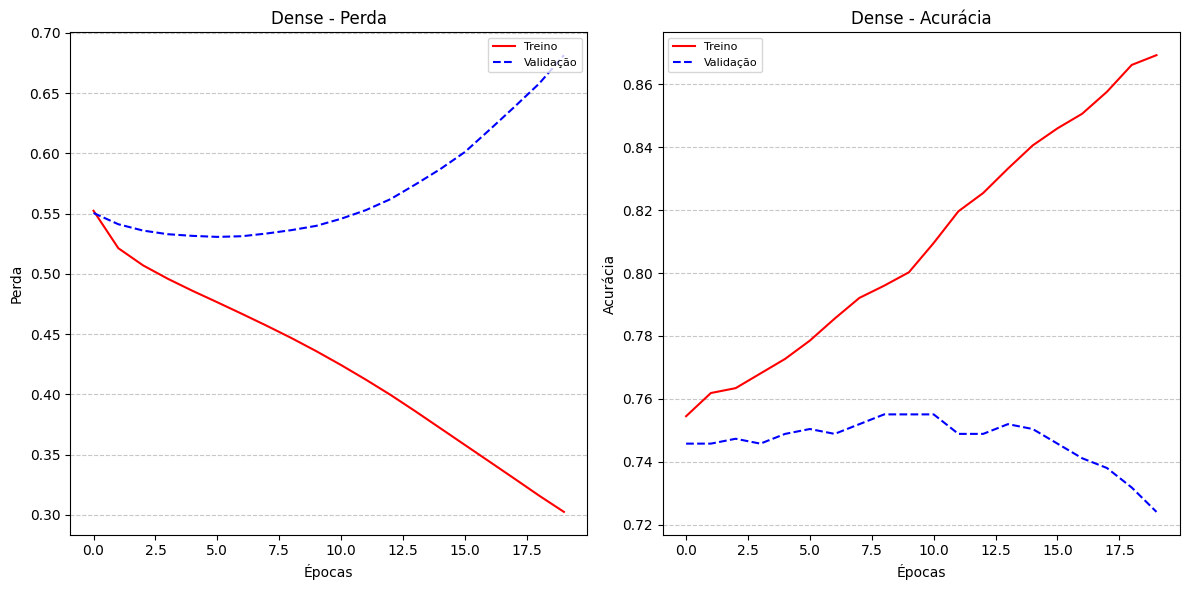

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history, title):
    plt.figure(figsize=(12, 6))

    # Plotar a perda
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], 'r-', label='Treino')
    plt.plot(history.history['val_loss'], 'b--', label='Validação')
    plt.title(f'{title} - Perda')
    plt.xlabel('Épocas')
    plt.ylabel('Perda')
    plt.legend(loc='upper right', fontsize=8)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Plotar a precisão
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], 'r-', label='Treino')
    plt.plot(history.history['val_accuracy'], 'b--', label='Validação')
    plt.title(f'{title} - Acurácia')
    plt.xlabel('Épocas')
    plt.ylabel('Acurácia')
    plt.legend(loc='upper left', fontsize=8)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

plot_training_history(dense_history, 'Dense')

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Métricas - Treino
Acurácia: 0.8641
Precisão: 0.7805
Recall (Sensibilidade): 0.6080
F1-Score: 0.6835
AUC: 0.8789

Matriz de Confusão:
[[2312  133]
 [ 305  473]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      2445
           1       0.78      0.61      0.68       778

    accuracy                           0.86      3223
   macro avg       0.83      0.78      0.80      3223
weighted avg       0.86      0.86      0.86      3223



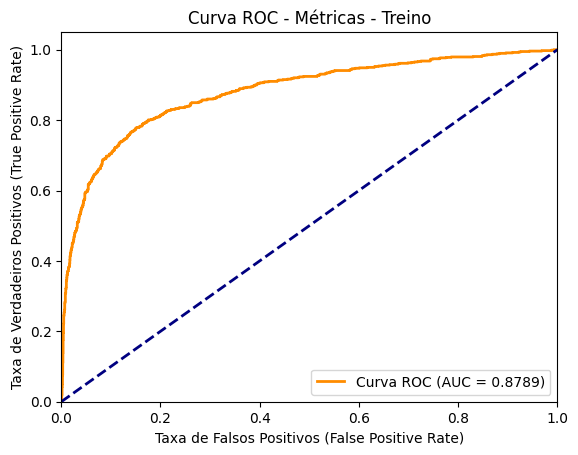

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Métricas - OOT
Acurácia: 0.7113
Precisão: 0.3663
Recall (Sensibilidade): 0.2665
F1-Score: 0.3085
AUC: 0.5996

Matriz de Confusão:
[[894 154]
 [245  89]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.78      0.85      0.82      1048
           1       0.37      0.27      0.31       334

    accuracy                           0.71      1382
   macro avg       0.58      0.56      0.56      1382
weighted avg       0.68      0.71      0.69      1382



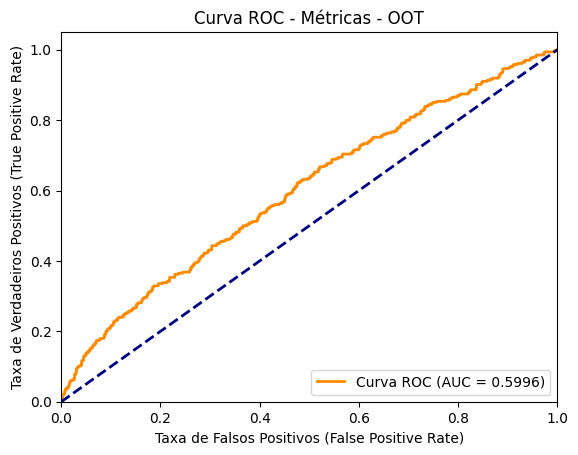

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Função para exibir as métricas de classificação e plotar a Curva ROC
def exibir_metricas_classificacao(y_true, y_pred, y_probs, title):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probs)  # Calcular AUC com base nas probabilidades
    conf_matrix = confusion_matrix(y_true, y_pred)

    print(f"\n{title}")
    print(f"Acurácia: {acc:.4f}")
    print(f"Precisão: {prec:.4f}")
    print(f"Recall (Sensibilidade): {rec:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("\nMatriz de Confusão:")
    print(conf_matrix)
    print("\nRelatório de Classificação:")
    print(classification_report(y_true, y_pred))

    # Plotar a Curva ROC
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (False Positive Rate)')
    plt.ylabel('Taxa de Verdadeiros Positivos (True Positive Rate)')
    plt.title(f'Curva ROC - {title}')
    plt.legend(loc="lower right")
    plt.show()

# Fazer previsões no conjunto de dados de treino
y_train_pred = (dense_model.predict(X_train_transformed) > 0.5).astype(int).squeeze()
y_train_probs = dense_model.predict(X_train_transformed).squeeze()  # Probabilidades para calcular AUC

# Exibir as métricas para o conjunto de dados de treino
exibir_metricas_classificacao(y_train, y_train_pred, y_train_probs, 'Métricas - Treino')

# Fazer previsões no conjunto de dados de OOT
y_oot_pred = (dense_model.predict(X_oot_transformed) > 0.5).astype(int).squeeze()
y_oot_probs = dense_model.predict(X_oot_transformed).squeeze()  # Probabilidades para calcular AUC

# Exibir as métricas para o conjunto de dados de OOT
exibir_metricas_classificacao(y_oot, y_oot_pred, y_oot_probs, 'Métricas - OOT')


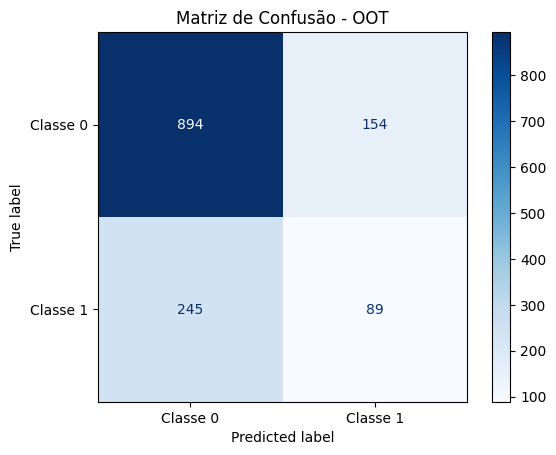

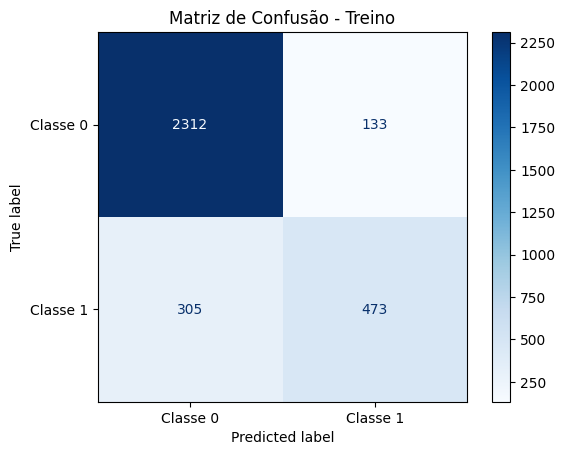

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_confusion_matrix(y_true, y_pred, title='Matriz de Confusão'):
    # Calcular a matriz de confusão
    cm = confusion_matrix(y_true, y_pred)

    # Criar o gráfico da matriz de confusão
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Classe 0', 'Classe 1'])

    # Plotar a matriz de confusão
    disp.plot(cmap=plt.cm.Blues, values_format='d')
    plt.title(title)
    plt.show()

# Usar a função para plotar a matriz de confusão para o conjunto OOT
plot_confusion_matrix(y_oot, y_oot_pred, title='Matriz de Confusão - OOT')

# Usar a função para plotar a matriz de confusão para o conjunto de treino
plot_confusion_matrix(y_train, y_train_pred, title='Matriz de Confusão - Treino')



#### Modelo 2 - Deep Learning Redes Densas com regularização
###### L2, Dropout, + epochs, Otimizador Adam, Early Stoping, Batch Normalization

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, BatchNormalization, Input
from keras import regularizers
from keras.optimizers import RMSprop, Adam  # Adicionando Adam aqui
from keras.callbacks import EarlyStopping
import tensorflow as tf
import numpy as np
import random

# Fixando a semente de aleatoriedade
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)
# Criar o modelo
dense_model = Sequential()
dense_model.add(Input(shape=(X_train_transformed.shape[1],))) # Camada de entrada com forma definida a partir dos dados de treino
dense_model.add(Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.0001)))
dense_model.add(BatchNormalization()) # BatchNormalization para estabilizar e acelerar o treinamento
dense_model.add(Dropout(0.5))
dense_model.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.0001)))
dense_model.add(BatchNormalization())
dense_model.add(Dropout(0.5))
dense_model.add(Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.0001)))
dense_model.add(Dense(1, activation='sigmoid'))

# Compilar o modelo com um otimizador diferente
dense_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])
# Treinar o modelo com EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

dense_history = dense_model.fit(
    X_train_transformed, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

# Avaliar o modelo no conjunto de teste
test_loss, test_accuracy = dense_model.evaluate(X_oot_transformed, y_oot)
print(f'Test Loss: {test_loss}, Test Accuracy: {test_accuracy}')


Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3096 - loss: 1.5244 - val_accuracy: 0.3829 - val_loss: 0.7578
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3478 - loss: 1.3245 - val_accuracy: 0.3907 - val_loss: 0.7673
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3830 - loss: 1.1603 - val_accuracy: 0.5147 - val_loss: 0.7350
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4260 - loss: 1.0248 - val_accuracy: 0.5705 - val_loss: 0.6933
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4857 - loss: 0.9226 - val_accuracy: 0.6310 - val_loss: 0.6579
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5153 - loss: 0.8537 - val_accuracy: 0.6791 - val_loss: 0.6326
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5441 - loss: 0.7797 - val_accuracy: 0.7039 - val_loss: 0.6138
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5713 - loss: 0.7695 - val_accuracy: 0.7070 - val_loss:

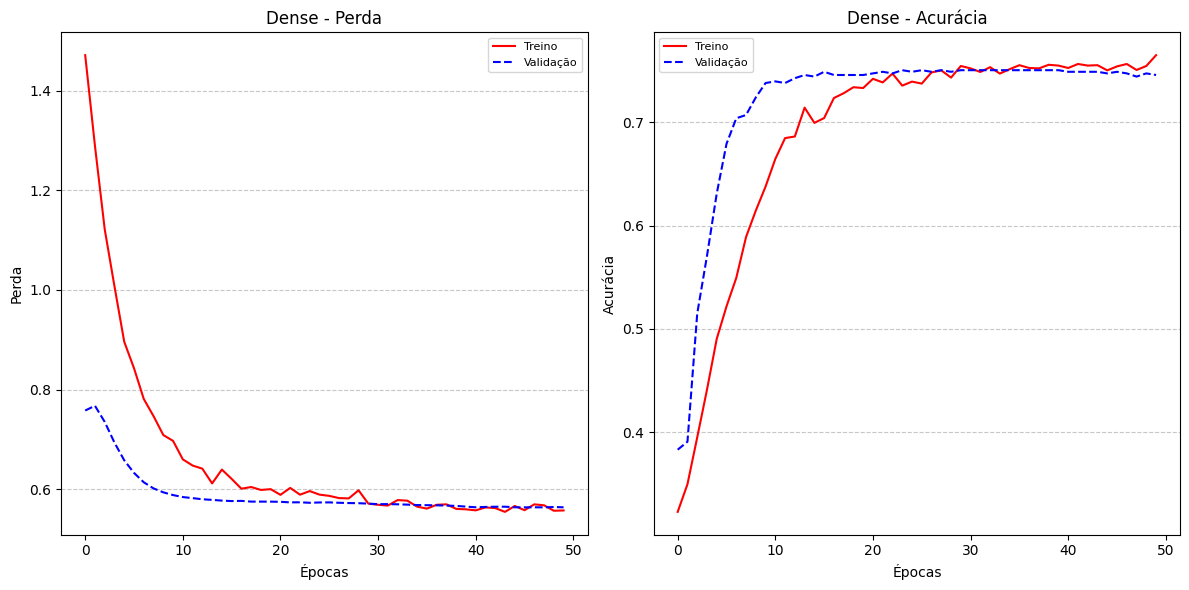

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history, title):
    plt.figure(figsize=(12, 6))

    # Plotar a perda
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], 'r-', label='Treino')
    plt.plot(history.history['val_loss'], 'b--', label='Validação')
    plt.title(f'{title} - Perda')
    plt.xlabel('Épocas')
    plt.ylabel('Perda')
    plt.legend(loc='upper right', fontsize=8)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Plotar a precisão
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], 'r-', label='Treino')
    plt.plot(history.history['val_accuracy'], 'b--', label='Validação')
    plt.title(f'{title} - Acurácia')
    plt.xlabel('Épocas')
    plt.ylabel('Acurácia')
    plt.legend(loc='upper left', fontsize=8)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

plot_training_history(dense_history, 'Dense')

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Métricas - Treino
Acurácia: 0.6292
Precisão: 0.3622
Recall: 0.7044
F1-Score: 0.4784
AUC: 0.7147

Matriz de Confusão:
[[1480  965]
 [ 230  548]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.87      0.61      0.71      2445
           1       0.36      0.70      0.48       778

    accuracy                           0.63      3223
   macro avg       0.61      0.65      0.60      3223
weighted avg       0.74      0.63      0.66      3223



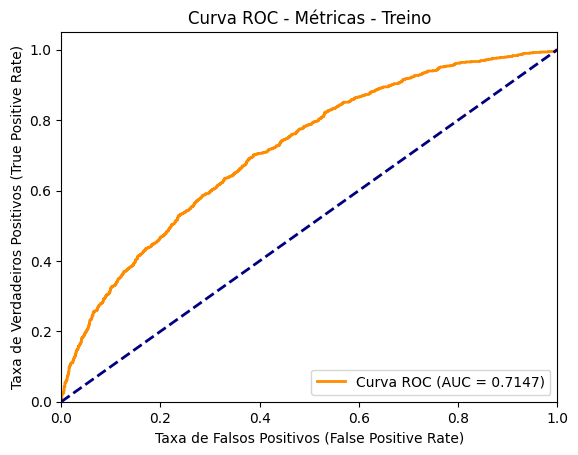

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Métricas - OOT
Acurácia: 0.5796
Precisão: 0.3005
Recall: 0.5569
F1-Score: 0.3903
AUC: 0.6129

Matriz de Confusão:
[[615 433]
 [148 186]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.81      0.59      0.68      1048
           1       0.30      0.56      0.39       334

    accuracy                           0.58      1382
   macro avg       0.55      0.57      0.53      1382
weighted avg       0.68      0.58      0.61      1382



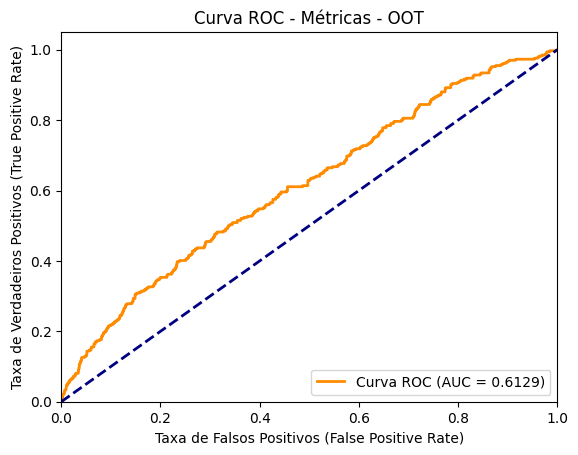

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Função para exibir as métricas de classificação e plotar a Curva ROC
def exibir_metricas_classificacao(y_true, y_pred, y_probs, title):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probs)  # Calcular AUC com base nas probabilidades
    conf_matrix = confusion_matrix(y_true, y_pred)

    print(f"\n{title}")
    print(f"Acurácia: {acc:.4f}")
    print(f"Precisão: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("\nMatriz de Confusão:")
    print(conf_matrix)
    print("\nRelatório de Classificação:")
    print(classification_report(y_true, y_pred))

    # Plotar a Curva ROC
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (False Positive Rate)')
    plt.ylabel('Taxa de Verdadeiros Positivos (True Positive Rate)')
    plt.title(f'Curva ROC - {title}')
    plt.legend(loc="lower right")
    plt.show()

# Fazer previsões no conjunto de dados de treino (probabilidades e predições)
y_train_probs = dense_model.predict(X_train_transformed).squeeze()  # Probabilidades para calcular AUC
y_train_pred = (y_train_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.5

# Exibir as métricas e a curva ROC para o conjunto de dados de treino
exibir_metricas_classificacao(y_train, y_train_pred, y_train_probs, 'Métricas - Treino')

# Fazer previsões no conjunto de dados de OOT (probabilidades e predições)
y_oot_probs = dense_model.predict(X_oot_transformed).squeeze()  # Probabilidades para calcular AUC
y_oot_pred = (y_oot_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.5

# Exibir as métricas e a curva ROC para o conjunto de dados de OOT
exibir_metricas_classificacao(y_oot, y_oot_pred, y_oot_probs, 'Métricas - OOT')


44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


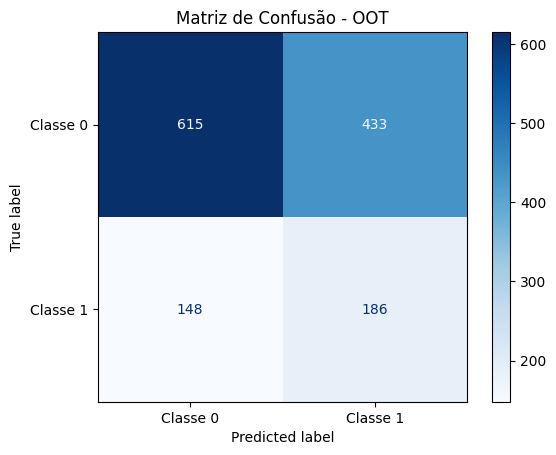

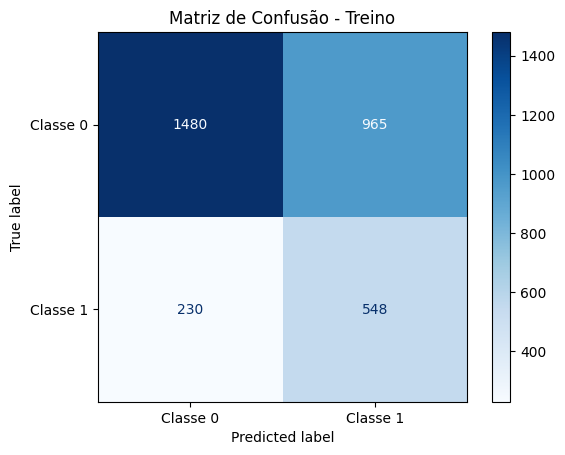

In [ ]:
# Fazer previsões no conjunto de dados OOT
y_oot_probs = dense_model.predict(X_oot_transformed).squeeze()  # Probabilidades para calcular AUC
y_oot_pred = (y_oot_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.22

# Fazer previsões no conjunto de dados de treino
y_train_probs = dense_model.predict(X_train_transformed).squeeze()  # Probabilidades para calcular AUC
y_train_pred = (y_train_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.22

# Usar a função para plotar a matriz de confusão para o conjunto OOT
plot_confusion_matrix(y_oot, y_oot_pred, title='Matriz de Confusão - OOT')

# Usar a função para plotar a matriz de confusão para o conjunto de treino
plot_confusion_matrix(y_train, y_train_pred, title='Matriz de Confusão - Treino')



#### Modelo 3 - Deep Learning Redes CNN com regularização
###### Dropout, MaxPooling, Otimizador Adam, Early Stoping, Batch Normalization

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.6661 - loss: 0.6890 - val_accuracy: 0.7225 - val_loss: 0.6777
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7266 - loss: 0.5882 - val_accuracy: 0.7442 - val_loss: 0.6682
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.7550 - loss: 0.5627 - val_accuracy: 0.7457 - val_loss: 0.6547
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.7551 - loss: 0.5618 - val_accuracy: 0.7457 - val_loss: 0.6380
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.7619 - loss: 0.5532 - val_accuracy: 0.7457 - val_loss: 0.6216
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.7571 - loss: 0.5574 - val_accuracy: 0.7457 - val_loss: 0.5984
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.7578 - loss: 0.5429 - val_accuracy: 0.7457 - val_loss: 0.5744
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.7616 - loss: 0.5298 - val_accuracy: 0.7411 - v

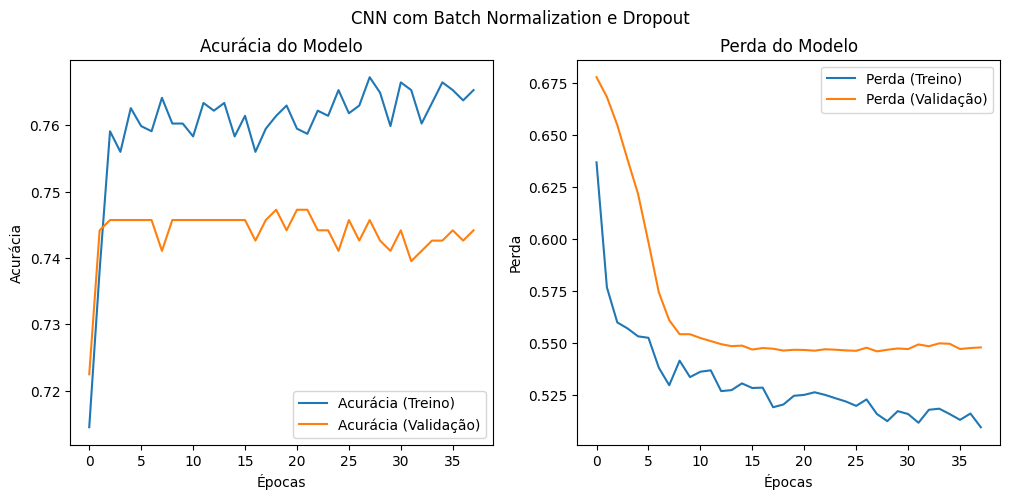

In [ ]:
import random
import numpy as np
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
import matplotlib.pyplot as plt

# Fixando a semente de aleatoriedade para reprodutibilidade
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# Redimensionar os dados de entrada para 3D: (n_amostras, comprimento_sequência, 1)
X_train_cnn = np.expand_dims(X_train_transformed, axis=2)
X_oot_cnn = np.expand_dims(X_oot_transformed, axis=2)

# Definir a arquitetura da CNN com Batch Normalization e Dropout
cnn_model = Sequential()
cnn_model.add(Conv1D(128, kernel_size=2, activation='relu', input_shape=(X_train_cnn.shape[1], 1)))
cnn_model.add(BatchNormalization())  # Adiciona Batch Normalization para estabilizar o aprendizado
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Conv1D(64, kernel_size=2, activation='relu'))
cnn_model.add(Dropout(0.5))  # Adiciona Dropout para evitar overfitting
cnn_model.add(MaxPooling1D(pool_size=2))
cnn_model.add(Flatten())
cnn_model.add(Dense(32, activation='relu'))
cnn_model.add(Dense(1, activation='sigmoid'))

# Compilar o modelo
cnn_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

# Treinar o modelo com EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

# Função para plotar o histórico de treinamento
def plot_training_history(history, title):
    plt.figure(figsize=(12, 5))

    # Plotar a perda
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Perda (Treino)')
    plt.plot(history.history['val_loss'], label='Perda (Validação)')
    plt.title('Perda do Modelo')
    plt.xlabel('Épocas')
    plt.ylabel('Perda')
    plt.legend()

    # Plotar a acurácia
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Acurácia (Treino)')
    plt.plot(history.history['val_accuracy'], label='Acurácia (Validação)')
    plt.title('Acurácia do Modelo')
    plt.xlabel('Épocas')
    plt.ylabel('Acurácia')
    plt.legend()

    plt.suptitle(title)
    plt.show()

# Plotar o histórico de treinamento
plot_training_history(cnn_history, 'CNN com Batch Normalization e Dropout')


101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Métricas - Treino
Acurácia: 0.5312
Precisão: 0.3108
Recall: 0.7738
F1-Score: 0.4435
AUC: 0.6822

Matriz de Confusão:
[[1110 1335]
 [ 176  602]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.86      0.45      0.60      2445
           1       0.31      0.77      0.44       778

    accuracy                           0.53      3223
   macro avg       0.59      0.61      0.52      3223
weighted avg       0.73      0.53      0.56      3223



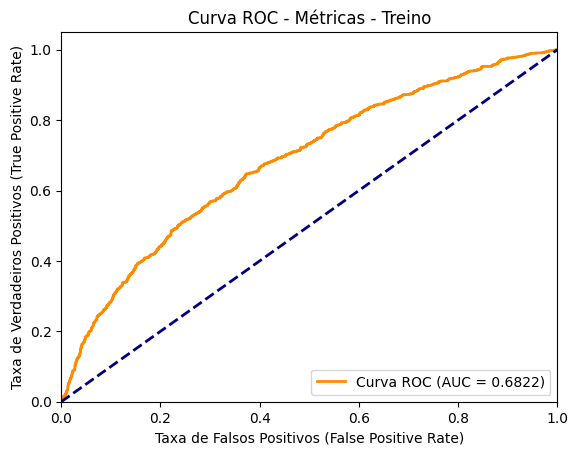

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

Métricas - OOT
Acurácia: 0.5232
Precisão: 0.3011
Recall: 0.7365
F1-Score: 0.4275
AUC: 0.6465

Matriz de Confusão:
[[477 571]
 [ 88 246]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.84      0.46      0.59      1048
           1       0.30      0.74      0.43       334

    accuracy                           0.52      1382
   macro avg       0.57      0.60      0.51      1382
weighted avg       0.71      0.52      0.55      1382



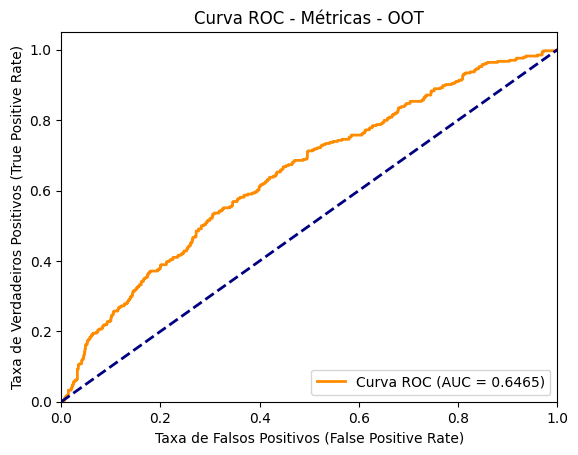

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Função para exibir as métricas de classificação e plotar a Curva ROC
def exibir_metricas_classificacao(y_true, y_pred, y_probs, title):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probs)  # Calcular AUC com base nas probabilidades
    conf_matrix = confusion_matrix(y_true, y_pred)

    print(f"\n{title}")
    print(f"Acurácia: {acc:.4f}")
    print(f"Precisão: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("\nMatriz de Confusão:")
    print(conf_matrix)
    print("\nRelatório de Classificação:")
    print(classification_report(y_true, y_pred))

    # Plotar a Curva ROC
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (False Positive Rate)')
    plt.ylabel('Taxa de Verdadeiros Positivos (True Positive Rate)')
    plt.title(f'Curva ROC - {title}')
    plt.legend(loc="lower right")
    plt.show()

# Fazer previsões no conjunto de dados de treino (probabilidades e predições)
y_train_probs = cnn_model.predict(X_train_cnn).squeeze()  # Probabilidades para calcular AUC
y_train_pred = (y_train_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.5

# Exibir as métricas e a curva ROC para o conjunto de dados de treino
exibir_metricas_classificacao(y_train, y_train_pred, y_train_probs, 'Métricas - Treino')

# Fazer previsões no conjunto de dados de OOT (probabilidades e predições)
y_oot_probs = cnn_model.predict(X_oot_cnn).squeeze()  # Probabilidades para calcular AUC
y_oot_pred = (y_oot_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.5

# Exibir as métricas e a curva ROC para o conjunto de dados de OOT
exibir_metricas_classificacao(y_oot, y_oot_pred, y_oot_probs, 'Métricas - OOT')


44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


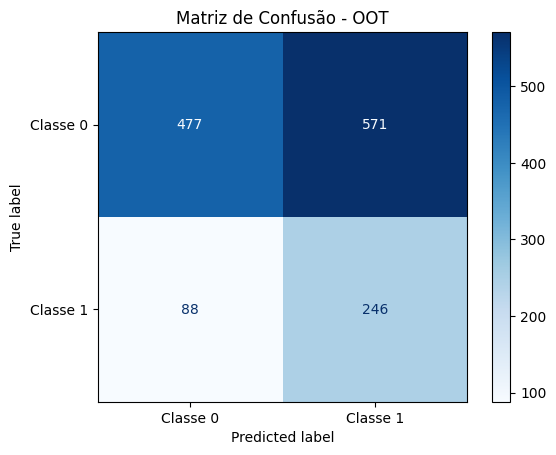

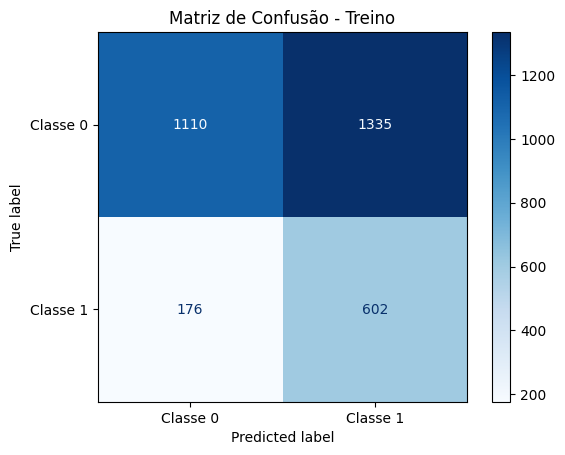

Custo sem Modelo - Treino: 2022800
Custo com Modelo - Treino: 2627200
Economia Efetiva - Treino: -604400
Custo sem Modelo - OOT: 868400
Custo com Modelo - OOT: 1132000
Economia Efetiva - OOT: -263600


In [ ]:
# Fazer previsões no conjunto de dados OOT usando o modelo CNN
y_oot_probs = cnn_model.predict(X_oot_cnn).squeeze()  # Probabilidades para calcular AUC
y_oot_pred = (y_oot_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.22

# Fazer previsões no conjunto de dados de treino usando o modelo CNN
y_train_probs = cnn_model.predict(X_train_cnn).squeeze()  # Probabilidades para calcular AUC
y_train_pred = (y_train_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.22

# Usar a função para plotar a matriz de confusão para o conjunto OOT
plot_confusion_matrix(y_oot, y_oot_pred, title='Matriz de Confusão - OOT')

# Usar a função para plotar a matriz de confusão para o conjunto de treino
plot_confusion_matrix(y_train, y_train_pred, title='Matriz de Confusão - Treino')


# Chamar a função calcular_custo_prevencao
custo_train, custo_com_modelo_train, economia_efetiva_train, tp_train, fn_train, fp_train, tn_train = calcular_custo_prevencao(y_train, y_train_pred)
custo_oot, custo_com_modelo_oot, economia_efetiva_oot, tp_oot, fn_oot, fp_oot, tn_oot = calcular_custo_prevencao(y_oot, y_oot_pred)

# Exibir os resultados de custo_prevencao
print(f"Custo sem Modelo - Treino: {custo_train}")
print(f"Custo com Modelo - Treino: {custo_com_modelo_train}")
print(f"Economia Efetiva - Treino: {economia_efetiva_train}")

print(f"Custo sem Modelo - OOT: {custo_oot}")
print(f"Custo com Modelo - OOT: {custo_com_modelo_oot}")
print(f"Economia Efetiva - OOT: {economia_efetiva_oot}")




#### Modelo 4 - Deep Learning Redes LSTM com regularização
###### Dropout, Otimizador Adam, Early *Stoping*

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.5627 - loss: 0.6680 - val_accuracy: 0.7457 - val_loss: 0.5652
Epoch 2/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7600 - loss: 0.5493 - val_accuracy: 0.7457 - val_loss: 0.5538
Epoch 3/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7619 - loss: 0.5311 - val_accuracy: 0.7457 - val_loss: 0.5446
Epoch 4/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7601 - loss: 0.5247 - val_accuracy: 0.7473 - val_loss: 0.5380
Epoch 5/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7611 - loss: 0.5156 - val_accuracy: 0.7473 - val_loss: 0.5327
Epoch 6/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7609 - loss: 0.5128 - val_accuracy: 0.7519 - val_loss: 0.5297
Epoch 7/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7635 - loss: 0.5111 - val_accuracy: 0.7519 - val_loss: 0.5273
Epoch 8/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7662 - loss: 0.5059 - val_accuracy: 0.7535 - val_loss

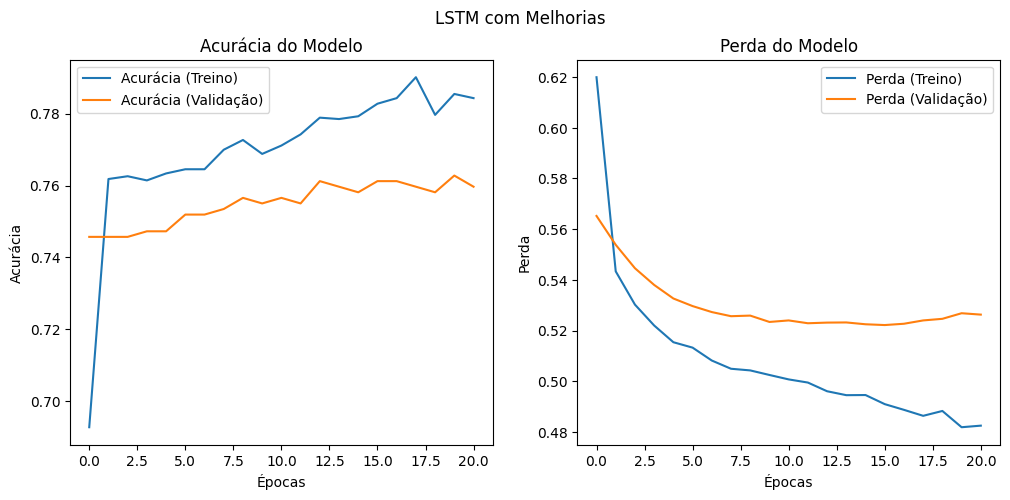

In [ ]:
import random
import numpy as np
import tensorflow as tf
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping

# Fixando a semente de aleatoriedade para reprodutibilidade
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# Definir o número de time_steps (cada ponto é independente neste caso)
time_steps = 1

# Redimensionar os dados de entrada para 3D: (n_amostras, time_steps, n_features)
X_train_rnn = X_train_transformed.to_numpy().reshape((X_train_transformed.shape[0], time_steps, X_train_transformed.shape[1]))
X_oot_rnn = X_oot_transformed.to_numpy().reshape((X_oot_transformed.shape[0], time_steps, X_oot_transformed.shape[1]))

# Definir a arquitetura da RNN com LSTM e Dropout
rnn_model = Sequential()
rnn_model.add(LSTM(100, input_shape=(time_steps, X_train_transformed.shape[1])))  # Aumentado para 50 neurônios
rnn_model.add(Dropout(0.5))  # Adicionando Dropout para evitar overfitting
rnn_model.add(Dense(32, activation='relu'))  # Camada densa adicional
rnn_model.add(Dense(1, activation='sigmoid'))  # Saída binária para classificação

# Compilar o modelo
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# EarlyStopping para evitar overfitting e interromper o treinamento cedo se a validação parar de melhorar
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Treinar o modelo com EarlyStopping e 50 épocas
rnn_history = rnn_model.fit(X_train_rnn, y_train, validation_split=0.2, epochs=50, batch_size=64, callbacks=[early_stopping])  # Aumentado para 50 épocas e batch_size 64

# Plotar o histórico de treinamento
plot_training_history(rnn_history, 'LSTM com Melhorias')

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Métricas - Treino
Acurácia: 0.6758
Precisão: 0.3948
Recall: 0.6440
F1-Score: 0.4895
AUC: 0.7223

Matriz de Confusão:
[[1677  768]
 [ 277  501]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.86      0.69      0.76      2445
           1       0.39      0.64      0.49       778

    accuracy                           0.68      3223
   macro avg       0.63      0.66      0.63      3223
weighted avg       0.75      0.68      0.70      3223



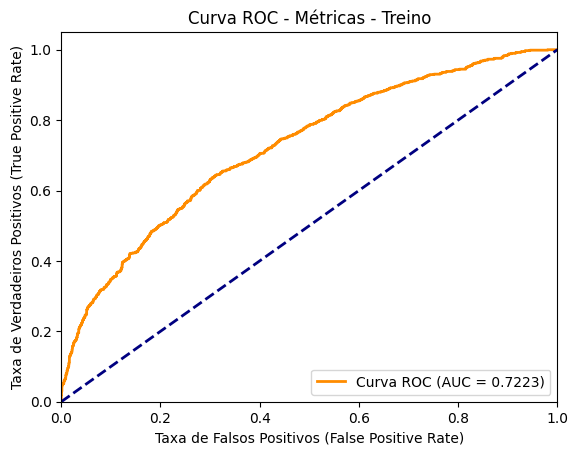

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

Métricas - OOT
Acurácia: 0.6440
Precisão: 0.3509
Recall: 0.5569
F1-Score: 0.4306
AUC: 0.6640

Matriz de Confusão:
[[704 344]
 [148 186]]

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.83      0.67      0.74      1048
           1       0.35      0.56      0.43       334

    accuracy                           0.64      1382
   macro avg       0.59      0.61      0.59      1382
weighted avg       0.71      0.64      0.67      1382



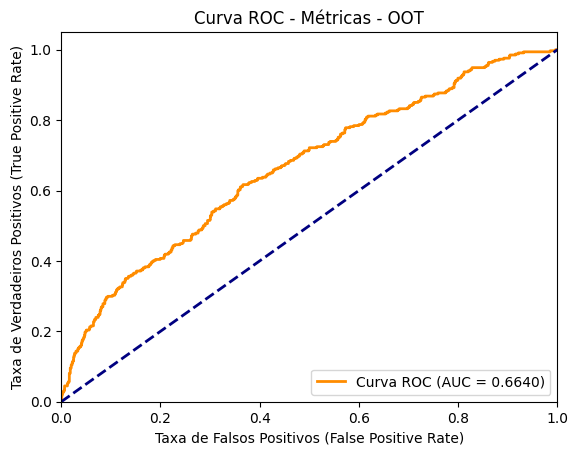

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Função para exibir as métricas de classificação e plotar a Curva ROC
def exibir_metricas_classificacao(y_true, y_pred, y_probs, title):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probs)  # Calcular AUC com base nas probabilidades
    conf_matrix = confusion_matrix(y_true, y_pred)

    print(f"\n{title}")
    print(f"Acurácia: {acc:.4f}")
    print(f"Precisão: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("\nMatriz de Confusão:")
    print(conf_matrix)
    print("\nRelatório de Classificação:")
    print(classification_report(y_true, y_pred))

    # Plotar a Curva ROC
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (False Positive Rate)')
    plt.ylabel('Taxa de Verdadeiros Positivos (True Positive Rate)')
    plt.title(f'Curva ROC - {title}')
    plt.legend(loc="lower right")
    plt.show()

# Fazer previsões no conjunto de dados de treino (probabilidades e predições)
y_train_probs = rnn_model.predict(X_train_rnn).squeeze()  # Probabilidades para calcular AUC
y_train_pred = (y_train_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.5

# Exibir as métricas e a curva ROC para o conjunto de dados de treino
exibir_metricas_classificacao(y_train, y_train_pred, y_train_probs, 'Métricas - Treino')

# Fazer previsões no conjunto de dados de OOT (probabilidades e predições)
y_oot_probs = rnn_model.predict(X_oot_rnn).squeeze()  # Probabilidades para calcular AUC
y_oot_pred = (y_oot_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.5

# Exibir as métricas e a curva ROC para o conjunto de dados de OOT
exibir_metricas_classificacao(y_oot, y_oot_pred, y_oot_probs, 'Métricas - OOT')


44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


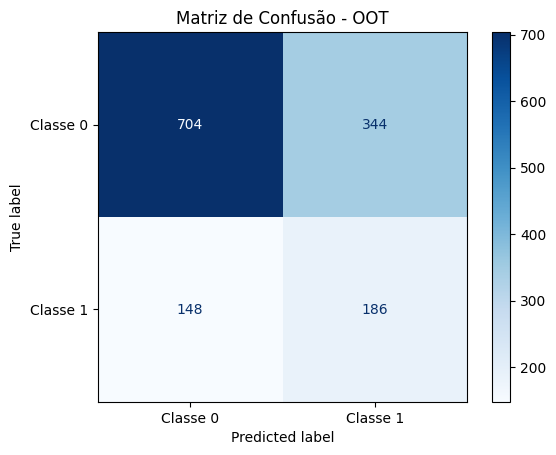

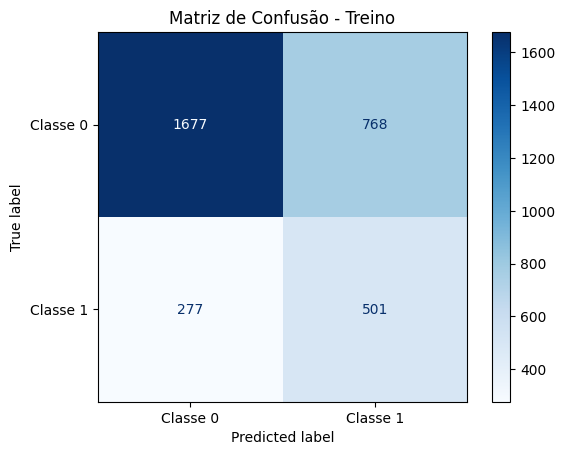

In [ ]:
# Fazer previsões no conjunto de dados OOT usando o modelo CNN
y_oot_probs = rnn_model.predict(X_oot_rnn).squeeze()  # Probabilidades para calcular AUC
y_oot_pred = (y_oot_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.22

# Fazer previsões no conjunto de dados de treino usando o modelo CNN
y_train_probs = rnn_model.predict(X_train_rnn).squeeze()  # Probabilidades para calcular AUC
y_train_pred = (y_train_probs > 0.22).astype(int).squeeze()  # Aplicar o limiar de 0.22

# Usar a função para plotar a matriz de confusão para o conjunto OOT
plot_confusion_matrix(y_oot, y_oot_pred, title='Matriz de Confusão - OOT')

# Usar a função para plotar a matriz de confusão para o conjunto de treino
plot_confusion_matrix(y_train, y_train_pred, title='Matriz de Confusão - Treino')



# 7. Conclusões

O comparativo completo dos modelos e a justificativa da escolha estão na apresentação final (`docs/apresentacao_final_tcc.pdf`).


Este projeto foi eficaz em identificar as variáveis relevantes associadas ao acidente com ocorrências graves (feridos graves ou mortos) em Minas Gerais na BR 381.
Foi aplicado desde modelo tradicional de estatística, até algoritmo de Machine Learning e Deep Learning. Independente do algoritmo utilizados todos apresentaram um desempenho aceitável, principalmente com relação ao desempenho  mais atenuado para Sensibilidade (que é a variável de interesse).
A conclusão é de que este trabalho fornece um modelo preditivo que pode ser usado pela Polícia Rodoviária Federal para acionar equipes de suporte e mobilização de recursos mais eficientes.
O modelo mais adequado para o problema de negócio foi a Regressão Logística do Machine Learning onde foi aplicado ajuste no ponte de corte, selecionado os melhores hiperparâmetros apresentou um acerto preditivo satisfatório e mais intensificado para Sensibilidade com 70% e um AUC de 68%, além de generalizar bem e ter um resultado similar ao comparar a Base de Treino e Teste, não houve overfting.
Com relação ao custo vale ressaltar que devido o problema de negócio o foco é a predição do Target1, logo o custo gerado pelo  volume mais alto em Falso positivo é melhor do que o custo gerado pelo menor numero de Falso negativo. Se aplicar o modelo em produção o custo será de R$1.099.200 , gerando um acréscimo de R$230.800 se comparado a performance sem o modelo.
As variáveis compõem o modelo e explicam a ocorrência com feridos graves ou mortos (lembrando que para as categóricas foi aplicado o One Hot Enconder)
Pessoas
Veículos
Causa acidente agg
Tipo pista
Tipo acidente categ


* As variáveis excluídas do teste do modelo foram devido à alta granularidade ou por não ter um IV relevante ou por não ser significativa no modelo.


# 8. Trabalhos Futuros

O modelo ainda apresenta oportunidade de melhora visto que  embora a Sensibilidade esteja satisfatória o Precision está baixo, indicando um volume alto de Falso Positivo.
Oportunidades futuras a se considerar para aplicar no modelo são:

Exploração de Novas features: Features de novas fontes de dados (perfil da vitíma), dados mais detalhados de condição meteorológica como bases de clima tempo.

Abordagem de  ténicas de balanceamento: SMOTE

Aplicação de outras otimizações de Hiper parâmetros: para melhor ajuste do trade off de Sensibilidade e Especificidade
